In [1]:
# Low-RAM clone: run from the repo root (data/, runs/, experiments/ and the ember package are resolved from there).
import os
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "ember").is_dir() and _root != _root.parent:
    _root = _root.parent
assert (_root / "ember").is_dir(), "repo root (the folder with ember/) not found above the cwd"
os.chdir(_root)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
print(f"cwd: {_root}")

cwd: /homes/orip/repos/personal/nlp_proj


# EMBER end to end, background-whitened + target-sharpened: §3.1 Sparse MF → §3.2 concept features → §3.3 embedding erasure (varnnz: variable per-feature sparsity)

> **Variable per-feature sparsity (varnnz) variant** of `ancient_rome_whitened.ipynb`. Step 3.1 no longer keeps exactly
> $\lceil s|V^*|\rceil$ tokens in every feature (row of $Y$): `experiments/variable_sparsity/varsparse.py`
> (`SparsityConfig`, `fit_best_of`) gives each feature its own width. Everything after the fit is unchanged.
>
> - **Modes** (`BUDGET_MODE`). `"per_row"`: feature $i$ keeps $m_i$ tokens, drawn once from `BUDGET_DIST` = `"constant"` |
>   `"uniform"` (`UNIFORM_RANGE`) | `"loguniform"` (`LOGUNIFORM_RANGE`) | `"gaussian"` (`GAUSS_STD`), and assigned to the rows at
>   random (`BUDGET_ASSIGN = "random"`) or re-sorted by each row's participation ratio during the early phase (`"matched"`,
>   every `MATCH_EVERY` iterations). `"pooled_rownorm"`: one pool of $M$ entries scored $|Y_{i,t}|/\|Y_{i,:}\|$, which favours
>   peaky rows. `"pooled_contrib"`: one pool scored $|Y_{i,t}|\,\|\mathbf z_i\|$, which favours high-energy features.
> - **Same total budget.** Every mode keeps $M = k\lceil s|V^*|\rceil$ non-zeros in total; only their split over the
>   features changes, so reconstruction errors stay comparable with the fixed-budget fit and across configs.
> - **Guardrails.** Per-feature floor / cap (`ROW_FLOOR`, `ROW_CAP`, fractions of $|V^*|$). Annealing (`ANNEAL`): every
>   feature starts at `ANNEAL_START` = 10% of $|V^*|$ and shrinks geometrically to its target over `ANNEAL_ITERS`. Noisy
>   top-$m$ (`NOISE_SIGMA0`, 0 = off): support scores $\times\,e^{\sigma_t\varepsilon}$, $\sigma_t$ decaying linearly to 0 over
>   `NOISE_ITERS` (None = the anneal length); kept values are always the exact least-squares values.
> - **Early phase and restarts.** Best-loss tracking and patience start only once anneal / noise / matching are over
>   (`t_free`), so the denser early phase is never returned as the best fit. `N_RESTARTS` fits (seeds `SEED`, `SEED+1`, …)
>   run and the one with the lowest relative error is kept; 3.1.d shows the per-restart table (error, widths, top $\rho$,
>   concept coverage).
> - **New cells.** 3.1.e″ (width histogram, loss curve, width vs. support coherence) and 3.2.e″ ($F_C$ widths / coherence /
>   $\rho$ vs. the rest). Caches: `RUN_DIR` and `ORIG_DIR` (the usual names + `_varnnz-<slug>`), slug = `SPARSITY_CFG.slug()`, so fixed-budget caches are never touched.
> - **Module updates.** `pooled_*` and `BUDGET_ASSIGN = "matched"` raise `NotImplementedError` until `varsparse.py`
>   implements them. The hyperparameter cell runs `importlib.reload(varsparse)`, so re-running it picks up a new version
>   of the module without a kernel restart.
>
> **Suggested staging.** *Stage A* (whitened Gemma, no Gemini: stop before 3.2.c): sweep `BUDGET_DIST` ∈ {constant,
> uniform, loguniform, gaussian} × `ANNEAL` on/off × noise on/off (`NOISE_SIGMA0` = 0.5 / 0), plus both pooled modes,
> 3 restarts each; compare relative error, top $\rho$, concept coverage and support coherence. *Stage B*: the full judge
> and erasure (3.2.c onwards and Step 3.3) for the top 2–3 configs.

> **Background-whitened + target-sharpened variant** of `ember_three_steps_ancient_rome.ipynb` (method: `Instructions.txt`, code:
> `experiments/whitening/sharpen.py`). Same concept, data, hyperparameters and seed. Step 3.1 factorizes
> $X = (E_{V^*} - \mathbf 1\boldsymbol\mu_B^\top)\,M$ with $M = W\,S_\eta^{\gamma/2}$ instead of the raw rows:
>
> - $W = Q(\Lambda+\epsilon I)^{-1/2}Q^\top$ whitens against a **background** that is fixed per model (`BACKGROUND`:
>   `"wiki"` = token types of a large Wikipedia sample, `"full"` = whole vocabulary), not against $V^*$ itself.
> - $S_\eta = (1-\eta)\,\tfrac1m U_C^\top U_C + \eta I$ is the second moment of the whitened **target** rows (`TARGET`:
>   all tokens of the concept's English Wikipedia page, or those minus the Wikipedia background types). Its eigenvalues
>   are enrichment ratios; $S_\eta^{\gamma/2}$ stretches enriched directions (`GAMMA` = 0: whitening only).
> - **3.1.c′** builds the transform `T` (`T.forward`, `T.unmap`, `T.matrix`). **3.1.d** fits `Z`, `Y` on $X$;
>   **3.1.d′** fits `Z0`, `Y0` on the raw matrix (cached once per notebook in `ORIG_DIR`). 3.1.e/f report both.
> - **3.2** selects $F_C$ from the transformed fit; **3.2.e′** runs the same selection on the original fit (`F_C0`);
>   **3.2.w** matches the two fits' features by support overlap and writes `RUN_DIR/summary.json`.
> - **3.3** maps the concept part back exactly, $\mathbf c_t = T^{-1}\tilde{\mathbf c}_t$ (the mean cancels), and edits the raw embeddings.
>
> **Runs.** Every expensive result is cached in `RUN_DIR = runs/whiten/<model>/<concept>/<BACKGROUND>_<TARGET>_g<GAMMA>/`
> (`smf.pt`, `judge.json`, `mc.json`, `gen.json`, `summary.json`); the original fit and its judge in `ORIG_DIR`.
> `SMOKE = True` makes a quick end-to-end pass into `..._smoke`. `scripts/run_overnight.py --queue runs/whiten/queue.json`
> runs the sweep headless (`--param BACKGROUND=... GAMMA=...`), stops before Step 3.3 for the sweep entries, and skips the
> §3.4 cells (tagged `skip-overnight`).


Paper: *Don't Forget Your Embeddings: Robust Knowledge Erasure via Precise Editing of Embeddings*
(Suslik, Shafran, Geva, EMNLP Findings 2026). This notebook runs the three stages of §3 for one concept,
using the paper's default hyperparameters. Each stage is split into small blocks, and each block starts
with a note on what it does.

| Step | Paper section | What happens | Repo code reused |
|---|---|---|---|
| **3.1** | Finding Embedding Features with Sparse MF | factorize $E_{V^*}^\top \approx ZY$ with WTA-sparse $Y$ | `SparseMatrixFactorization`, `fit_with_ridge` |
| **3.2** | Identifying Concept-Related Features | mass ratio $\rho_i \ge \tau$, then a two-stage Gemini judge → $F_C$ | `compute_embedding_stats`, prompts from `ember/interpret_features.py` |
| **3.3** | Erasing Concept-Related Features | $\mathbf e_t \leftarrow \mathbf e_t - \delta \sum_{i\in F_C} Y_{i,t}\,\mathbf z_i$ for concept tokens | same math as `ember/erasure/embed_edit.py` |

**Notation.** Paper $Z \in \mathbb R^{d\times k}$ = code `F_`; paper $Y \in \mathbb R^{k\times|V^*|}$ = code `G_.T`.
In this notebook, `Z` and `Y` use the paper's shapes.

**Requirements:** a GPU, `HF_TOKEN` (only needed for gated models such as Llama), and a Gemini API key for Step 3.2.

---
## 0. Setup

### 0.1 Hyperparameters (paper defaults)

| Symbol | Value | Source |
|---|---|---|
| $k$ (rank) | 100 for Gemma-2-2B-it, 200 for Llama-3.1-8B-Instruct | App. A.1 |
| $s$ (WTA sparsity on $Y$) | 0.01, so each factor keeps $\lceil 0.01\,|V^*| \rceil$ tokens | App. A.1 |
| $\lambda$ (ridge) | $10^{-4}$ | App. A.1 |
| $T$ / patience / tol | 20,000 iters / 500 iters / $10^{-4}$ | App. A.1 |
| $\|S_C\| = \|S_N\|$ | 300 sentences each (`data/*_sentences.json`) | §4.1 |
| $\tau$ (mass-ratio threshold) | 2.0 | App. A.3 |
| judge confidence | ≥ 0.85, with 20 tokens per feature | App. A.3 |
| $\delta$ (edit strength) | tuned per concept over {0.5, 1, 2, 5, 10, 50, 100, 200} | App. C.3 |

In [2]:
import gc
import json
import math
import os
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from dotenv import load_dotenv
from tqdm.auto import tqdm

load_dotenv()  # HF_TOKEN / GEMINI_API_KEY from .env, if present
pd.set_option("display.max_colwidth", 200)

# ---- what to erase ------------------------------------------------------
CONCEPT = "Ancient Rome"
MODEL_NAME = "google/gemma-2-2b-it"     # or "meta-llama/Llama-3.1-8B-Instruct"
SEED = 42

# ---- Step 3.1: Sparse MF (App. A.1) -------------------------------------
RANK = 200 if "llama" in MODEL_NAME.lower() else 100   # k
SPARSITY = 0.01          # s
RIDGE = 1e-4             # lambda
MAX_ITER = 20_000        # T
PATIENCE = 200

# ---- Step 3.1 variant: variable per-feature sparsity (experiments/variable_sparsity/varsparse.py) ----
BUDGET_MODE = "per_row"            # "per_row" | "pooled_rownorm" (|Y|/||Y_row||: peaky rows) | "pooled_contrib" (|Y|*||z||: high-energy features)
BUDGET_DIST = "uniform"            # per_row: "constant" | "uniform" | "loguniform" | "gaussian"
BUDGET_ASSIGN = "random"           # per_row: "random" | "matched" (budgets re-sorted by participation ratio early on)
UNIFORM_RANGE = (0.005, 0.015)     # U(lo, hi), fractions of |V*|
LOGUNIFORM_RANGE = (0.0025, 0.04)  # 16x spread, geometric mean 1%
GAUSS_STD = 0.003                  # N(s, std)
ROW_FLOOR = 0.002                  # per-feature min fraction of |V*|
ROW_CAP = 0.05                     # per-feature max fraction of |V*|
ANNEAL = False                      # budgets start at ANNEAL_START per feature, shrink geometrically to the target
ANNEAL_START = 0.10
ANNEAL_ITERS = 1500
NOISE_SIGMA0 = 0.5                 # noisy top-m: scores * exp(sigma_t * eps); 0 = off
NOISE_ITERS = 300                 # None: ANNEAL_ITERS if ANNEAL else 1000
MATCH_EVERY = 50                   # BUDGET_ASSIGN = "matched": re-sort period (iterations)
MATCH_ITERS = None                 # "matched": re-sort phase length; None = the anneal / noise phase (1000 if both off)
N_RESTARTS = 1                     # seeds SEED .. SEED + N_RESTARTS - 1; the lowest relative error is kept

# ---- Step 3.2: feature selection (App. A.3) -----------------------------
TAU = 2.0
CONFIDENCE = 0.85
TOP_K_TOKENS = 20
GEMINI_MODEL = "models/gemini-3.5-flash-lite"   # repo default; the paper used Gemini-2.5-Flash-Lite

# ---- Step 3.3: erasure (App. C.3) ---------------------------------------
DELTA_GRID = [0.5, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0, 200.0]
DELTA = 10.0             # Harry Potter / Gemma value, not tuned for Ancient Rome; see the sweep in 3.3.f

# ---- background whitening + target sharpening (Instructions.txt, experiments/whitening/sharpen.py) ----
import re
import sys

sys.path.insert(0, "experiments/whitening")
from sharpen import BackgroundWhitener, Sharpener, Transform, principal_angle_sines

BACKGROUND = "wiki"      # "wiki" (Wikipedia token types) or "full" (whole vocabulary)
TARGET = "page"          # "page" (all tokens of the concept's English Wikipedia page) or "page_minus_wiki"
GAMMA = 1.0              # sharpening strength; 0 = background whitening only
MODEL_SLUG = "gemma"     # "gemma" | "llama": selects experiments/whitening/data/<MODEL_SLUG>
SMOKE = False            # True: quick end-to-end pass (short fit, 3 judged features, tiny evals)

# ---- overrides from scripts/run_overnight.py --param NAME=VALUE (set in an injected first cell) ----
globals().update(globals().get("_OVERRIDES", {}))
assert BACKGROUND in ("wiki", "full"), BACKGROUND
assert TARGET in ("page", "page_minus_wiki"), TARGET
assert GAMMA >= 0, GAMMA
assert MODEL_SLUG == ("llama" if "llama" in MODEL_NAME.lower() else "gemma"), (MODEL_SLUG, MODEL_NAME)

WH_DIR = Path("experiments/whitening/data") / MODEL_SLUG
_defaults_path = WH_DIR / "defaults.json"
if _defaults_path.exists():
    defaults = json.loads(_defaults_path.read_text())
    print(f"whitening defaults from {_defaults_path}: {defaults}")
else:
    defaults = {"eps_rel": 1e-3, "eta": 0.2}
    print(f"{_defaults_path} not found: built-in defaults {defaults}")
ETA = globals().get("_OVERRIDES", {}).get("ETA", defaults["eta"])              # target shrinkage (fixed hyperparameter)
EPS_REL = globals().get("_OVERRIDES", {}).get("EPS_REL", defaults["eps_rel"])  # eps = EPS_REL * mean(background eigenvalues)

if SMOKE:
    MAX_ITER, PATIENCE = 50, 5
    ANNEAL_ITERS, N_RESTARTS = 20, 2
    NOISE_ITERS = 20 if NOISE_ITERS is None else min(NOISE_ITERS, 20)   # fit_best_of needs MAX_ITER > t_free
    MATCH_ITERS = 20 if MATCH_ITERS is None else min(MATCH_ITERS, 20)

# ---- variable-sparsity config (built after overrides / SMOKE) ----
if "experiments/variable_sparsity" not in sys.path:
    sys.path.insert(0, "experiments/variable_sparsity")
import importlib

import varsparse

importlib.reload(varsparse)  # re-running this cell picks up module updates (pooled modes, matched assignment)
from varsparse import SparsityConfig, fit_best_of

SPARSITY_CFG = SparsityConfig(
    mode=BUDGET_MODE, dist=BUDGET_DIST, assign=BUDGET_ASSIGN, sparsity=SPARSITY,
    uniform_range=UNIFORM_RANGE, loguniform_range=LOGUNIFORM_RANGE, gauss_std=GAUSS_STD, floor=ROW_FLOOR, cap=ROW_CAP,
    anneal=ANNEAL, anneal_start=ANNEAL_START, anneal_iters=ANNEAL_ITERS,
    noise_sigma0=NOISE_SIGMA0, noise_iters=NOISE_ITERS, match_every=MATCH_EVERY, match_iters=MATCH_ITERS,
)
print(f"sparsity config: {SPARSITY_CFG.slug()}  (restarts={N_RESTARTS}, t_free={SPARSITY_CFG.t_free})")

# ---- run directories: resume caches ----
concept_slug = re.sub(r"\W+", "_", CONCEPT).strip("_")
_smoke = "_smoke" if SMOKE else ""
RUN_DIR = Path("runs/whiten") / MODEL_SLUG / concept_slug / f"{BACKGROUND}_{TARGET}_g{GAMMA:g}_varnnz-{SPARSITY_CFG.slug()}{_smoke}"
ORIG_DIR = Path("runs/whiten") / MODEL_SLUG / concept_slug / f"original_varnnz-{SPARSITY_CFG.slug()}{_smoke}"   # original fit + judge, shared by all whitening configs
RUN_DIR.mkdir(parents=True, exist_ok=True)
ORIG_DIR.mkdir(parents=True, exist_ok=True)


def load_json(path: Path, default):
    return json.loads(path.read_text()) if path.exists() else default


def save_json(path: Path, obj) -> None:
    tmp = path.with_suffix(path.suffix + ".tmp")   # write then rename, so a crash never leaves a half file
    tmp.write_text(json.dumps(obj, indent=1, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
    tmp.replace(path)


def invalidate(directory: Path, names) -> None:
    """Move stale cache files aside (<name>.stale) so they are recomputed."""
    for name in names:
        p = directory / name
        if p.exists():
            p.replace(p.with_name(p.name + ".stale"))
            print(f"  moved stale {p} -> {p.name}.stale")

concepts = [e["concept"] for e in json.loads(Path("data/concept_sentences.json").read_text())]
assert CONCEPT in concepts, f"{CONCEPT!r} is not one of: {concepts}"
print(f"concept={CONCEPT!r} | model={MODEL_NAME} | k={RANK}")
print(f"background={BACKGROUND} | target={TARGET} | gamma={GAMMA:g} | eta={ETA:g} | eps_rel={EPS_REL:g} | "
      f"smoke={SMOKE} | run dir={RUN_DIR} | original-fit dir={ORIG_DIR}")

whitening defaults from experiments/whitening/data/gemma/defaults.json: {'eps_rel': 0.0001, 'eta': 0.05, 'gamma': 1.0, 'background': 'wiki', 'target': 'page', 'chosen_by': 'per concept, rank the 5 eta configs (gamma=1, target=page, wiki background) on each of auc, purity, coverage, rho_max (1 = best, ties averaged); mean over 4 metrics x 3 concepts; lowest mean rank wins, ties -> smaller eta', 'mean_rank': {'0.05': 2.375, '0.1': 2.625, '0.2': 2.625, '0.3': 3.75, '0.5': 3.625}, 'table': [{'concept': 'Harry Potter', 'config': 'raw', 'eta': None, 'gamma': 0.0, 'rho_max': 25.952961539649255, 'n_tau': 34, 'purity': 0.875, 'coverage': 0.413903743315508, 'auc': 0.6352346199705871, 'rel_err': 0.9158350825309753, 'fit_s': 21.3}, {'concept': 'Harry Potter', 'config': 'wiki_eps0.0001_g0', 'eta': None, 'gamma': 0.0, 'rho_max': 82.03510360623223, 'n_tau': 26, 'purity': 0.9375, 'coverage': 0.29411764705882354, 'auc': 0.5882676819657264, 'rel_err': 0.9422608613967896, 'fit_s': 47.9}, {'concept': 'Har

/homes/orip/.conda/envs/Ember/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 0.2 Gemini API key

Step 3.2 is the only step that calls Gemini. You can paste your key below or put `GEMINI_API_KEY=...`
in `.env`. Clear the key from this cell before you commit or share the notebook.

In [3]:
GEMINI_API_KEY = ""  # paste here, or leave empty to use .env / the environment

if GEMINI_API_KEY:
    os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY
assert any(os.getenv(k) for k in ("GOOGLE_API_KEY", "GEMINI_API_TOKEN", "GEMINI_API_KEY")), \
    "No Gemini key found: Step 3.2 needs one."
print("Gemini key found.")

Gemini key found.


### 0.3 Repo imports

These are the building blocks the paper's pipeline uses. Reusing them means the notebook gives the same
results as `ember.train_mf_features`, `ember.interpret_features`, and `ember.run_erasure`.

In [4]:
from llm_utils.activation_generator import ActivationGenerator, extract_token_ids_sample_ids_and_labels
from transformers import AutoTokenizer

from ember.erasure.model_loader import load_hf_model
from ember.evals.mc import evaluate_mc_generation, prepare_mc_items
from ember.evals.model_wrap import WrappedHFModel
from ember.interpret_features import (
    MEMBERSHIP_PROMPT,
    TOKENS_DESC_SYS,
    SimpleGeminiClient,
    classify_membership_with_desc,
    get_description,
)
from ember.local_datasets import ConceptDataset, load_mc_qa_items, load_open_qa_examples
from ember.timing import Timer
from ember.utils import (
    SparseMatrixFactorization,
    _safe_model_name,
    build_token_label_codes,
    collect_feature_rows_for_embeddings,
    compute_embedding_stats,
    fit_with_ridge,
    get_embedding_matrix,
    get_special_token_ids,
    resolve_device,
    set_seed,
)

set_seed(SEED)
# DEVICE = resolve_device("auto")
# This host's vGPU reports CUDA as available but prohibits compute, so force CPU.
DEVICE = "cpu"
os.environ["EMBER_DEVICE"] = "cpu"  # load_hf_model reads this
print(f"device: {DEVICE}")

/homes/orip/.conda/envs/Ember/lib/python3.10/site-packages/google/api_core/_python_version_support.py:242: FutureWarning: You are using a non-supported Python version (3.10.21). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


device: cpu


---
# Step 3.1: Finding embedding features with Sparse Matrix Factorization

**Goal:** split each token embedding $\mathbf e_t$ into a sum of a few shared directions, so that
semantically related tokens (e.g. *Harry*, *Hogwarts*, *wand*) share a feature:

$$E_{V^*}^\top \approx Z\,Y,\qquad Z\in\mathbb R^{d\times k}\ \text{(dense features)},\quad Y\in\mathbb R^{k\times|V^*|}\ \text{(WTA-sparse coefficients)}$$

The hard winner-takes-all (WTA) constraint on the rows of $Y$ means each feature $\mathbf z_i$ is used by only
1% of the tokens in $V^*$. That is why a feature can be specific to one concept.

### 3.1.a Load the model (TransformerLens)

The pipeline reads $E$ through TransformerLens. **Note:** for Gemma, TL folds the $\sqrt{d}$ embedding
multiplier into `W_E`, so the factorization runs in this *scaled* space. Step 3.3 accounts for that
when it writes back into the HF weights.

In [5]:
# Low-RAM: steps 3.1-3.2 use only W_E and the tokenizer, so no TransformerLens model is built.
# W_E is read straight from the checkpoint and matches TL's: Gemma = HF embedding * sqrt(d_model), Llama = as stored;
# TL skips writing-weight centering for RMSNorm models. E_DTYPE is the dtype this notebook's TL model used.
import json
import math
from types import SimpleNamespace

from huggingface_hub import hf_hub_download
from huggingface_hub.utils import EntryNotFoundError
from safetensors import safe_open

E_DTYPE = torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer.pad_token is None:  # Llama-3: TL also pads with eos
    tokenizer.pad_token = tokenizer.eos_token


def load_input_embeddings(model_name: str) -> torch.Tensor:
    """Reads only model.embed_tokens.weight from the checkpoint (no model is built)."""
    try:
        index = json.loads(Path(hf_hub_download(model_name, "model.safetensors.index.json")).read_text())
        shard = index["weight_map"]["model.embed_tokens.weight"]
    except EntryNotFoundError:  # single-file checkpoint
        shard = "model.safetensors"
    with safe_open(hf_hub_download(model_name, shard), framework="pt") as f:
        return f.get_tensor("model.embed_tokens.weight")


class TokenizerOnly:
    """The parts of a HookedTransformer that 3.1-3.2 use: tokenizer, to_tokens, to_str_tokens."""

    def __init__(self, tok):
        self.tokenizer = tok

    def to_tokens(self, prompts, padding_side="left"):
        self.tokenizer.padding_side = padding_side
        return self.tokenizer(prompts, return_tensors="pt", padding=True)["input_ids"]  # BOS added by the tokenizer

    def to_str_tokens(self, ids):
        return self.tokenizer.batch_decode(torch.as_tensor(ids).reshape(-1, 1), clean_up_tokenization_spaces=False)


tl_model = TokenizerOnly(tokenizer)  # keeps the old names, so the cells below run unchanged
act_generator = SimpleNamespace(model=tl_model, data_device="cpu")

E = load_input_embeddings(MODEL_NAME).to(E_DTYPE)  # (|V|, d)
if "gemma" in MODEL_NAME.lower():
    E.mul_(torch.tensor(math.sqrt(E.shape[1]), dtype=E_DTYPE))  # in place: no second (|V|, d) copy
VOCAB_SIZE, D_MODEL = E.shape
print(f"E: {tuple(E.shape)}  dtype={E.dtype}")

E: (256000, 2304)  dtype=torch.float32


### 3.1.b Build $S_C \cup S_N$ and the token set $V^*$

- $S_C$: 300 Wikipedia sentences about the concept. $S_N$: 300 neutral Wikipedia sentences.
- $V^*$: the unique non-special token ids in $S_C \cup S_N$. The model factorizes only these rows of $E$,
  which is cheaper and keeps the factorization focused on the concept. The neutral tokens let Step 3.2
  tell concept features apart from general ones.

In [6]:
dataset = ConceptDataset(concept_name=CONCEPT, neutral_sample_seed=42)
token_ids_all, sample_ids, labels_all = extract_token_ids_sample_ids_and_labels(dataset, act_generator)

special = get_special_token_ids(tl_model)
vstar_ids = sorted({int(t) for t in token_ids_all.tolist()} - special)

n_concept_sents = sum(lbl == CONCEPT for _, lbl in dataset)
print(f"|S_C| = {n_concept_sents}   |S_N| = {len(dataset) - n_concept_sents}")
print(f"token occurrences = {len(token_ids_all)}  ->  |V*| = {len(vstar_ids)} "
      f"({len(vstar_ids) / VOCAB_SIZE:.2%} of the vocabulary)")

Extracting token IDs:   0%|          | 0/120 [00:00<?, ?it/s]

Extracting token IDs: 100%|██████████| 120/120 [00:00<00:00, 590.41it/s]

|S_C| = 300   |S_N| = 300
token occurrences = 16935  ->  |V*| = 4760 (1.86% of the vocabulary)


### 3.1.c Build the data matrix $A = E_{V^*}^\top$

Each column of $A$ is one token's embedding.

In [7]:
E_vstar = E.index_select(0, torch.tensor(vstar_ids, device=E.device)).detach().float()  # (|V*|, d)
A = E_vstar.T.contiguous().to(DEVICE)                                                      # (d, |V*|)

print(f"A: {tuple(A.shape)}  (d x |V*|)")
_n_s = math.ceil(SPARSITY * len(vstar_ids))
print(f"total budget M = k * ceil(s*|V*|) = {RANK} x {_n_s} = {RANK * _n_s} non-zeros; per-feature widths vary in "
      f"[{max(1, math.ceil(ROW_FLOOR * len(vstar_ids)))}, {math.floor(ROW_CAP * len(vstar_ids))}]  ({SPARSITY_CFG.slug()})")

A: (2304, 4760)  (d x |V*|)
total budget M = k * ceil(s*|V*|) = 100 x 48 = 4800 non-zeros; per-feature widths vary in [10, 238]  (per_row-uniform-nz0.5-ca11a0)


### 3.1.c′ Background whitening and target sharpening

Instructions steps 1–4, in the row convention of the notebook (rows are tokens; `sharpen.py`):

$$U = (E_{V^*} - \mathbf 1\boldsymbol\mu_B^\top)\,W,\quad W = Q(\Lambda+\epsilon I)^{-1/2}Q^\top;\qquad
S_\eta = (1-\eta)\,\tfrac1m U_C^\top U_C + \eta I = P\,\mathrm{diag}(g)\,P^\top;\qquad X = U\,S_\eta^{\gamma/2}$$

1. **Background** ($\boldsymbol\mu_B$, $Q$, $\Lambda$ of $\Sigma_B$) is loaded from `WH_DIR/bg_<BACKGROUND>_stats.pt`. It was computed once per
   model, in the same space as `E` (TL `W_E`: Gemma rows already × $\sqrt d$; Llama unscaled). $\epsilon$ = `EPS_REL` × mean($\Lambda$).
   Check: $W\Sigma_B W = Q\,\mathrm{diag}\big(\lambda/(\lambda+\epsilon)\big)Q^\top \approx I$, except along the smallest
   eigenvalues, which $\epsilon$ deliberately damps.
2. **Whitening** centres on $\boldsymbol\mu_B$ (not on the mean of $V^*$), so the concept's shift away from the background stays in the data.
3. **Target**: the token ids of the concept's Wikipedia page (`WH_DIR/targets/<concept>.json`, key `TARGET`), whitened with the
   same $W$. The second moment is taken around 0, so it includes that shift. $g_j$ are **enrichment ratios** ($g_j > 1$: the target
   varies more than the background along $\mathbf p_j$); $\eta$ = `ETA` puts a floor under the directions the target does not use.
4. **Sharpening** with $S_\eta^{\gamma/2}$ applies one fixed map to every row of $V^*$, concept and neutral alike. `GAMMA = 0` skips it.

The combined map is `T` (`Transform`): `T.forward(rows)` $= (\text{rows}-\boldsymbol\mu_B)\,M$ with $M$ = `T.matrix` $= W S_\eta^{\gamma/2}$, and
`T.unmap(z)` $= z\,S_\eta^{-\gamma/2}W^{-1}$ maps directions back. `transform(rows)` is the float32 helper the analysis cells use.

**Diagnostics.** The largest enrichment ratios, and the contrastive-PCA directions $\mathbf p_1,\dots,\mathbf p_5$: the whitened
Wikipedia background token types (`bg_wiki_types.json`) projected on each, top 15 shown (`*` = in the target set). If they are
concept tokens, the signal is there before any factorization. With `GAMMA = 0` the same diagnostics use a $\gamma=1$ sharpener that is
not applied.

From here on `A` is $X^\top$; `E_vstar_orig` (= `E_vstar`) keeps the raw rows and `A0` the raw data matrix.

In [8]:
# Instructions steps 1-4: background whitening W, target second moment S_eta, sharpening S_eta^(gamma/2). float64, CPU.
E_vstar_orig = E_vstar                                    # raw rows (Gemma: TL-scaled), for the original fit 3.1.d'
A0 = E_vstar.T.contiguous().to(DEVICE)                    # (d, |V*|) raw

# ---- step 1: background statistics (built once per model by experiments/whitening) ----
BG_PATH = WH_DIR / f"bg_{BACKGROUND}_stats.pt"
TARGETS_PATH = WH_DIR / "targets" / f"{concept_slug}.json"
for _p, _what in [(BG_PATH, f"background statistics ({BACKGROUND})"), (TARGETS_PATH, f"target token ids for {CONCEPT!r}")]:
    if not _p.exists():
        raise FileNotFoundError(f"{_p} is missing: the {_what} must be built first (experiments/whitening)")
stats_bg = torch.load(BG_PATH, map_location="cpu")
missing_keys = {"mu", "lam", "Q"} - set(stats_bg)
assert not missing_keys, f"{BG_PATH} lacks {missing_keys}"
assert stats_bg["Q"].shape == (D_MODEL, D_MODEL), f"{BG_PATH}: Q is {tuple(stats_bg['Q'].shape)}, expected d = {D_MODEL}"
stats_bg = {k: (v.double() if torch.is_tensor(v) else v) for k, v in stats_bg.items()}
bw = BackgroundWhitener(stats_bg, EPS_REL)

lam_bg = stats_bg["lam"].clamp_min(0)
lam_desc = lam_bg.sort(descending=True).values
shrink = lam_desc / (lam_desc + bw.eps)                   # eigenvalues of W Sigma_B W
n95 = math.ceil(0.95 * len(lam_desc))
print(f"background {BACKGROUND}: n = {stats_bg.get('n', '?')} types, d = {D_MODEL}, eps = {EPS_REL:g} x mean(lam) = {bw.eps:.3e}")
print(f"W Sigma_B W ~ I: max |lam/(lam+eps) - 1| over the top 95% of directions = {(shrink[:n95] - 1).abs().max():.3e}, "
      f"overall = {(shrink - 1).abs().max():.3e} (the smallest eigenvalues are damped by eps on purpose)")
print(f"cond(Sigma_B) = {(lam_desc[0] / lam_desc[-1]).item() if lam_desc[-1] > 0 else float('inf'):.3e}   "
      f"cond(Sigma_B + eps I) = {((lam_desc[0] + bw.eps) / (lam_desc[-1] + bw.eps)).item():.3e}")

# ---- step 3: target rows, whitened ----
targets = json.loads(TARGETS_PATH.read_text())
assert TARGET in targets, f"{TARGETS_PATH} has keys {list(targets)}, not {TARGET!r}"
target_ids = sorted({int(t) for t in targets[TARGET] if 0 <= int(t) < VOCAB_SIZE} - set(special))
assert target_ids, f"{TARGETS_PATH}[{TARGET!r}] has no usable token ids"
E_target = E.index_select(0, torch.tensor(target_ids, device=E.device)).detach().double().cpu()   # (m, d), same space as E_vstar
U_target = bw.whiten(E_target)                                                                     # (m, d)
target_set, vstar_set = set(target_ids), set(vstar_ids)
_codes31 = build_token_label_codes(CONCEPT, dataset, tokenizer)
tc_ids = {t for t in vstar_ids if _codes31.get(t, 0) == 1}                                         # T_C (concept-only)
print(f"|target| = {len(target_ids)} ({TARGET})   in V*: {len(target_set & vstar_set)} / {len(vstar_ids)}   "
      f"concept-only T_C covered: {len(target_set & tc_ids)} / {len(tc_ids)}")

# ---- step 4: sharpening; T = whitening (+ sharpening) ----
sh = Sharpener(U_target, ETA, GAMMA) if GAMMA > 0 else None
sh_diag = sh if sh is not None else Sharpener(U_target, ETA, 1.0)   # gamma = 0: diagnostics only, never applied
T = Transform(bw, sh)


def transform(rows: torch.Tensor) -> torch.Tensor:
    """Rows (n, d) in the original (TL) space -> X-space: (rows - mu_B) W S_eta^(gamma/2), float32."""
    return T.forward(rows.detach().cpu()).float()


E_X = transform(E_vstar)                                  # (|V*|, d)
E_vstar_X = E_X                                           # survives 3.3.a; all analysis cells use it
A = E_X.T.contiguous().to(DEVICE)                         # (d, |V*|): 3.1.d fits on this
m_tilde = U_target.mean(0)                                # whitened target mean (the whitened shift Delta)
m_X = m_tilde if sh is None else m_tilde @ sh.Sp          # its image in X-space (= mean of transform(E_target))

# ---- checks ----
I_d = torch.eye(D_MODEL, dtype=torch.float64)
T_inv = bw.W_inv if sh is None else sh.Sm @ bw.W_inv      # row form: z = z~ @ T_inv
print(f"inverse: max |T.matrix @ (Sm @ W_inv) - I| = {(T.matrix @ T_inv - I_d).abs().max():.2e}")
print(f"row norms: raw mean {E_vstar.norm(dim=1).mean():.3f}   X-space mean {E_X.norm(dim=1).mean():.3f}   "
      f"cond(S_eta) = {(sh_diag.g[0] / sh_diag.g[-1]).item():.3e}   cond(T.matrix) = {torch.linalg.cond(T.matrix).item():.3e}")
del I_d

# ---- diagnostics: enrichment ratios ----
g_top = sh_diag.g[:10].tolist()
print(f"\nenrichment ratios g (eta = {ETA:g}; directions the target does not use sit at g = eta): top 10 = {', '.join(f'{v:.2f}' for v in g_top)}")
print(f"directions with g > 1: {int((sh_diag.g > 1).sum())} / {D_MODEL}   g > 2: {int((sh_diag.g > 2).sum())}   "
      f"stretch range applied: g^(gamma/2) in [{sh_diag.g[-1].item() ** (GAMMA / 2):.3f}, {sh_diag.g[0].item() ** (GAMMA / 2):.3f}]")

# ---- diagnostics: contrastive PCA on the whitened Wikipedia background types ----
N_CPCA, N_CPCA_TOK = 5, 15
WIKI_TYPES_PATH = WH_DIR / "bg_wiki_types.json"
if WIKI_TYPES_PATH.exists():
    wiki_ids = [int(t) for t in json.loads(WIKI_TYPES_PATH.read_text()) if 0 <= int(t) < VOCAB_SIZE]
    P5 = sh_diag.P[:, :N_CPCA]                                         # (d, 5)
    signs = torch.sign(m_tilde @ P5)                                   # orient each p_j towards the target mean
    signs[signs == 0] = 1.0
    M5 = bw.W @ (P5 * signs)                                           # whiten + project in one (d, 5) map
    scores = torch.cat([(E.index_select(0, torch.tensor(wiki_ids[i:i + 20_000], device=E.device)).detach().double().cpu()
                         - bw.mu) @ M5 for i in range(0, len(wiki_ids), 20_000)])   # (N_wiki, 5)
    cpca = {}
    for j in range(N_CPCA):
        top = torch.argsort(scores[:, j], descending=True)[:N_CPCA_TOK].tolist()
        toks = tokenizer.convert_ids_to_tokens([wiki_ids[i] for i in top])
        cpca[f"p{j + 1} (g={sh_diag.g[j]:.2f})"] = [f"{t}{' *' if wiki_ids[i] in target_set else ''}  {scores[i, j]:.2f}"
                                                   for t, i in zip(toks, top)]
    hit = {k: sum(s.split("  ")[0].endswith(" *") for s in v) for k, v in cpca.items()}
    print(f"\ncPCA: top {N_CPCA_TOK} of {len(wiki_ids)} whitened Wikipedia types on p_1..p_{N_CPCA} "
          f"(* = in the target set; per direction: {hit})")
    cpca_df = pd.DataFrame(cpca)
    cpca_df.index += 1
    display(cpca_df)
    del scores
else:
    print(f"\n{WIKI_TYPES_PATH} not found: cPCA diagnostic skipped")

print(f"\nA (transformed): {tuple(A.shape)}   A0 (raw): {tuple(A0.shape)}")

background wiki: n = 107472 types, d = 2304, eps = 0.0001 x mean(lam) = 2.712e-04
W Sigma_B W ~ I: max |lam/(lam+eps) - 1| over the top 95% of directions = 3.525e-04, overall = 2.512e-02 (the smallest eigenvalues are damped by eps on purpose)
cond(Sigma_B) = 3.314e+04   cond(Sigma_B + eps I) = 3.231e+04
|target| = 4210 (page)   in V*: 2690 / 4760   concept-only T_C covered: 1841 / 1850
inverse: max |T.matrix @ (Sm @ W_inv) - I| = 1.16e-14
row norms: raw mean 81.891   X-space mean 59.146   cond(S_eta) = 1.567e+02   cond(T.matrix) = 3.031e+02

enrichment ratios g (eta = 0.05; directions the target does not use sit at g = eta): top 10 = 10.92, 7.67, 7.08, 6.70, 6.07, 5.70, 5.39, 5.30, 5.03, 5.01
directions with g > 1: 926 / 2304   g > 2: 317   stretch range applied: g^(gamma/2) in [0.264, 3.305]

cPCA: top 15 of 107472 whitened Wikipedia types on p_1..p_5 (* = in the target set; per direction: {'p1 (g=10.92)': 15, 'p2 (g=7.67)': 13, 'p3 (g=7.08)': 15, 'p4 (g=6.70)': 15, 'p5 (g=6.07)': 14}

,p1 (g=10.92),p2 (g=7.67),p3 (g=7.08),p4 (g=6.70),p5 (g=6.07)
1,▁the * 23.12,▁existed * 5.75,3 * 24.40,6 * 16.72,", * 26.49"
2,▁that * 20.63,▁Waray 5.65,5 * 24.25,5 * 16.63,' * 23.92
3,▁with * 20.02,▁formed * 5.47,4 * 24.01,7 * 16.57,. * 23.75
4,▁in * 19.99,▁created * 5.46,2 * 23.76,3 * 16.08,""" * 20.98"
5,▁as * 19.11,▁known * 5.43,1 * 23.58,9 * 16.07,- * 19.13
6,▁from * 18.92,▁allowed * 5.32,7 * 23.33,4 * 16.07,; * 17.49
7,▁for * 18.92,▁gained * 5.19,6 * 23.26,8 * 16.06,: * 17.33
8,▁this * 18.83,▁established * 5.03,8 * 22.98,2 * 15.65,) * 16.99
9,▁to * 18.68,▁included * 4.96,9 * 22.26,1 * 15.54,"', * 16.35"
10,▁and * 17.69,▁started * 4.93,0 * 20.50,▁became * 13.62,""", * 15.30"



A (transformed): (2304, 4760)   A0 (raw): (2304, 4760)


### 3.1.d Fit Sparse MF (alternating least squares + variable-width WTA)

The fit alternates two closed-form ridge updates:

$$Z \leftarrow A Y^\top (Y Y^\top + \lambda I)^{-1},\qquad Y \leftarrow (Z^\top Z + \lambda I)^{-1} Z^\top A$$

**varnnz.** After each $Y$ update, WTA keeps the top $m_i$ entries of $|Y_{i,:}|$ for feature $i$ (`per_row`), or the top
entries of one pooled score over all features (`pooled_*`), instead of the same $\lceil s|V^*|\rceil$ in every row; the total
is always $M = k\lceil s|V^*|\rceil$. It also rescales between the two factors. Initialization is $\mathcal N(0,1)$. With
`ANNEAL`, every feature starts at `ANNEAL_START`$\cdot|V^*|$ tokens and shrinks to its target; with `NOISE_SIGMA0` > 0 the
support selection is perturbed early on. Both end at `t_free`, and only from there on does the fit track the best loss and
stop after 500 iterations without an improvement of more than $10^{-4}$. If the matrix inverse is singular, `fit_with_ridge`
retries with $\lambda \times 10$.

`fit_best_of` runs `N_RESTARTS` fits (seeds `SEED + r`) and keeps the lowest relative error $\|A-ZY\|_F/\|A\|_F$. The table has
one row per restart: error, ridge, iterations, widths (non-zeros per feature: min / median / max), and three concept
columns: `top_rho` (largest mass ratio $\rho_i$, 3.2.b), `n_rho>=tau` (features with $\rho_i\ge\tau$) and `concept_cov` (share
of the concept-only tokens that at least one of those features uses).

This is the slowest cell in Step 3.1 (about `N_RESTARTS` times the fixed-budget fit).

**Whitened/sharpened variant:** `A` is $X^\top$ from 3.1.c′, so `Z` and `Y` below are the transformed factorization that
everything downstream uses. The fit is cached in `RUN_DIR/smf.pt` together with its configuration (including `SPARSITY_CFG` and `N_RESTARTS`), the
restart table, and the budgets, widths and loss curve of the kept fit; a cache made with another
configuration (or another $V^*$) is moved aside as `*.stale` with the judge/MC/generation caches, and the fit reruns.


In [9]:
# Variable per-feature sparsity: N_RESTARTS fits of varsparse.VariableSparsityMF, the lowest relative error is kept.
# Resume: RUN_DIR/smf.pt is loaded when its configuration matches; otherwise it (and the caches built on it) are moved aside.

_codes_fit = np.array([_codes31.get(t, 0) for t in vstar_ids])


def concept_metrics(Y_: torch.Tensor) -> dict:
    """Per-restart concept columns: top rho, features with rho >= TAU, share of concept-only tokens they cover."""
    st = compute_embedding_stats(Y_.T, vstar_ids, _codes31, CONCEPT)
    rho = st["ratio_abs"].to_numpy(dtype=float)
    ok = np.isfinite(rho)
    hits = st["feature"].to_numpy()[ok & (rho >= TAU)]
    covered = (Y_[torch.as_tensor(hits, dtype=torch.long)] != 0).any(0).numpy() if len(hits) else np.zeros(len(vstar_ids), bool)
    n_c = int((_codes_fit == 1).sum())
    return {"top_rho": float(rho[ok].max()) if ok.any() else float("nan"),
            "n_rho>=tau": int(len(hits)),
            "concept_cov": float((covered & (_codes_fit == 1)).sum() / n_c) if n_c else float("nan")}


FIT_KEYS = ("Z", "Y", "ridge_used", "elapsed", "rel_err", "restarts", "budgets", "budgets_drawn", "nnz_per_row",
            "loss_history", "t_free", "best_restart")


def fit_cached(path: Path, A_mat: torch.Tensor, meta: dict, stale) -> dict:
    """fit_best_of on A_mat, cached in `path` with `meta`; a cache with other meta is moved aside with `stale`."""
    ck = torch.load(path, weights_only=False) if path.exists() else None
    if ck is not None and ck.get("meta") != meta:
        print(f"{path} was made with another configuration: re-fitting")
        invalidate(path.parent, stale)
        ck = None
    if ck is not None:
        out = {k: ck.get(k) for k in FIT_KEYS}
        print(f"loaded {path}")
    else:
        out = fit_best_of(A_mat, SPARSITY_CFG, RANK, N_RESTARTS, SEED, MAX_ITER, PATIENCE, RIDGE, DEVICE,
                          concept_metrics_fn=concept_metrics)
        out = {k: out[k] for k in FIT_KEYS}
        out["restarts"] = out["restarts"].to_dict("records")
        torch.save({**out, "meta": meta}, path)
    out["restarts"] = pd.DataFrame(out["restarts"])
    return out

SMF_PATH = RUN_DIR / "smf.pt"
fit_meta = {"model": MODEL_NAME, "vstar_ids": vstar_ids, "background": BACKGROUND, "target": TARGET, "gamma": GAMMA,
            "eta": ETA, "eps_rel": EPS_REL, "rank": RANK, "sparsity": SPARSITY, "ridge": RIDGE, "max_iter": MAX_ITER,
            "patience": PATIENCE, "seed": SEED, "n_target": len(target_ids),
            "sparsity_cfg": SPARSITY_CFG.to_meta(), "n_restarts": N_RESTARTS}
fit_out = fit_cached(SMF_PATH, A, fit_meta, ["smf.pt", "judge.json", "mc.json", "gen.json", "summary.json"])
Z, Y, ridge_used = fit_out["Z"], fit_out["Y"], fit_out["ridge_used"]   # (d, k) X-space features z~_i, (k, |V*|) sparse
t_fit = {"elapsed": fit_out["elapsed"]}
print(f"\nbest of {N_RESTARTS}: restart {fit_out['best_restart']}  rel_err={fit_out['rel_err']:.4f}  "
      f"fitted in {t_fit['elapsed']:.1f}s (lambda={ridge_used:g})  Z: {tuple(Z.shape)}  Y: {tuple(Y.shape)}")
display(fit_out["restarts"])


Iter    0: loss=17341210.000000  (early phase until iter 300, no best tracking yet)
Iter   50: loss=13768705.000000  (early phase until iter 300, no best tracking yet)
Iter  100: loss=13703681.000000  (early phase until iter 300, no best tracking yet)
Iter  150: loss=13656226.000000  (early phase until iter 300, no best tracking yet)
Iter  200: loss=13624424.000000  (early phase until iter 300, no best tracking yet)
Iter  250: loss=13606543.000000  (early phase until iter 300, no best tracking yet)
Iter  300: loss=13602115.000000  (best=13602115.000000, no_improve=0)
Iter  302: loss=13602111.000000  (best=13602111.000000, no_improve=1)
Iter  304: loss=13602109.000000  (best=13602108.000000, no_improve=1)
Iter  350: loss=13602117.000000  (best=13602108.000000, no_improve=47)
Iter  400: loss=13602127.000000  (best=13602108.000000, no_improve=97)
Iter  450: loss=13602127.000000  (best=13602108.000000, no_improve=147)
Iter  500: loss=13602126.000000  (best=13602108.000000, no_improve=197)


,restart,seed,rel_err,ridge,iters,nnz_total,nnz_min,nnz_median,nnz_max,seconds,top_rho,n_rho>=tau,concept_cov
0,0,42,0.87519,0.0001,504,4800,26,47.0,76,92.655537,29.577017,51,0.493514


### 3.1.d′ Reference fit on the original (untransformed) matrix

Same `SPARSITY_CFG`, restarts, settings and seeds, on the raw $A_0 = E_{V^*}^\top$. `Z0` and `Y0` are used only for comparison: 3.1.e/f (errors),
3.2.e′ (the raw fit's concept features `F_C0`) and 3.2.w (feature matching). Step 3.3 does not use them. The fit does not depend
on the whitening configuration, so it is cached in `ORIG_DIR/smf0.pt` (one per sparsity config: `ORIG_DIR` carries the
slug) and shared by every whitening configuration.

In [10]:
SMF0_PATH = ORIG_DIR / "smf0.pt"
fit0_meta = {"model": MODEL_NAME, "vstar_ids": vstar_ids, "rank": RANK, "sparsity": SPARSITY, "ridge": RIDGE,
             "max_iter": MAX_ITER, "patience": PATIENCE, "seed": SEED, "sparsity_cfg": SPARSITY_CFG.to_meta(),
             "n_restarts": N_RESTARTS}
fit0_out = fit_cached(SMF0_PATH, A0, fit0_meta, ["smf0.pt", "judge0.json"])   # same SPARSITY_CFG as 3.1.d
Z0, Y0, ridge_used0 = fit0_out["Z"], fit0_out["Y"], fit0_out["ridge_used"]   # (d, k) raw-space features, (k, |V*|) sparse
t_fit0 = {"elapsed": fit0_out["elapsed"]}
print(f"\nbest of {N_RESTARTS}: restart {fit0_out['best_restart']}  rel_err={fit0_out['rel_err']:.4f}  "
      f"fitted in {t_fit0['elapsed']:.1f}s (lambda={ridge_used0:g})  Z0: {tuple(Z0.shape)}  Y0: {tuple(Y0.shape)}")
display(fit0_out["restarts"])


Iter    0: loss=31636000.000000  (early phase until iter 300, no best tracking yet)
Iter   50: loss=27476756.000000  (early phase until iter 300, no best tracking yet)
Iter  100: loss=27215760.000000  (early phase until iter 300, no best tracking yet)
Iter  150: loss=27049598.000000  (early phase until iter 300, no best tracking yet)
Iter  200: loss=26950430.000000  (early phase until iter 300, no best tracking yet)
Iter  250: loss=26897428.000000  (early phase until iter 300, no best tracking yet)
Iter  300: loss=26881424.000000  (best=26881424.000000, no_improve=0)
Iter  301: loss=26881424.000000  (best=26881424.000000, no_improve=1)
Iter  309: loss=26881424.000000  (best=26881420.000000, no_improve=1)
Iter  350: loss=26881420.000000  (best=26881420.000000, no_improve=42)
Iter  400: loss=26881424.000000  (best=26881420.000000, no_improve=92)
Iter  450: loss=26881424.000000  (best=26881420.000000, no_improve=142)
Iter  500: loss=26881420.000000  (best=26881420.000000, no_improve=192)


,restart,seed,rel_err,ridge,iters,nnz_total,nnz_min,nnz_median,nnz_max,seconds,top_rho,n_rho>=tau,concept_cov
0,0,42,0.914947,0.0001,509,4800,26,47.0,76,86.487902,22.342494,40,0.472432


### 3.1.e Check the factorization

Reconstruction quality and sparsity. With variable sparsity the features no longer all use $\lceil s|V^*|\rceil$
tokens: widths range over [`ROW_FLOOR`, `ROW_CAP`] $\cdot|V^*|$ and only the total $M = k\lceil s|V^*|\rceil$ is fixed
(3.1.e″ shows the distribution). Tokens that
no feature covers are left as pure reconstruction error $\boldsymbol\varepsilon_t$.

Both fits are reported, each against its own data matrix. The two errors are not comparable in absolute terms: whitening
flattens the spectrum, so the transformed error is higher for any rank-$k$ model (the SVD baseline in 3.1.f shows by how much).

The second cell is the optional check of Instructions step 6: $|\cos(\tilde{\mathbf z}_i, \tilde{\mathbf m})|$ between each fitted factor
and the target mean in X-space ($\tilde{\mathbf m} = $ `m_X`). Concept factors should be among the highest; low values flag generic factors.


In [11]:
A_cpu, A0_cpu = A.cpu(), A0.cpu()
rel_err = (torch.norm(A_cpu - Z @ Y) / torch.norm(A_cpu)).item()        # transformed fit, X-space
rel_err0 = (torch.norm(A0_cpu - Z0 @ Y0) / torch.norm(A0_cpu)).item()   # original fit, raw space
nz = Y.abs() > 0
nz0 = Y0.abs() > 0

for name, err, mask in [("transformed", rel_err, nz), ("original", rel_err0, nz0)]:
    tokens_per_feature, features_per_token = mask.sum(1), mask.sum(0)
    print(f"[{name}] relative reconstruction error ||A - ZY||_F / ||A||_F = {err:.4f}")
    print(f"[{name}] tokens per feature : min={tokens_per_feature.min().item()}  median={tokens_per_feature.float().median():.0f}  max={tokens_per_feature.max().item()}  total={int(tokens_per_feature.sum())}")
    print(f"[{name}] features per token : mean={features_per_token.float().mean():.2f}  "
          f"max={features_per_token.max().item()}  uncovered tokens={int((features_per_token == 0).sum())}\n")

[transformed] relative reconstruction error ||A - ZY||_F / ||A||_F = 0.8752
[transformed] tokens per feature : min=26  median=47  max=76  total=4800
[transformed] features per token : mean=1.01  max=14  uncovered tokens=2146

[original] relative reconstruction error ||A - ZY||_F / ||A||_F = 0.9149
[original] tokens per feature : min=26  median=47  max=76  total=4800
[original] features per token : mean=1.01  max=4  uncovered tokens=1352



In [12]:
# Instructions step 6 (optional check): |cos| of each X-space factor with the target mean m_X.
cos_m = F.cosine_similarity(Z.double(), m_X.unsqueeze(1), dim=0).abs()       # (k,)
cos_m_order = torch.argsort(cos_m, descending=True).tolist()
print(f"|cos(z~_i, m_X)|: median={cos_m.median():.3f}  max={cos_m.max():.3f}  "
      f"(random-direction scale ~ {math.sqrt(2 / (math.pi * D_MODEL)):.3f})")
cos_m_df = pd.DataFrame({
    "feature": cos_m_order[:10],
    "|cos(z~, m_X)|": cos_m[cos_m_order[:10]].numpy(),
    "top tokens": [", ".join(tokenizer.convert_ids_to_tokens(
        [vstar_ids[j] for j in torch.argsort(Y[f].abs(), descending=True)[:8].tolist()])) for f in cos_m_order[:10]],
})
cos_m_df

|cos(z~_i, m_X)|: median=0.227  max=0.461  (random-direction scale ~ 0.017)


,feature,"|cos(z~, m_X)|",top tokens
0,26,0.461232,"▁on, ▁at, along, ▁in, ▁of, ▁to, ▁from, ▁for"
1,55,0.411665,"▁size, ▁rate, ▁length, ▁scale, ▁number, ▁range, ▁level, ▁distance"
2,50,0.399933,"▁provided, ▁supplied, ▁conducted, ▁performed, ▁taken, ▁done, ▁issued, ▁given"
3,94,0.391841,"▁land, ▁gold, ▁golden, ▁lands, land, ▁Golden, ▁Gold, ▁border"
4,13,0.385777,"▁good, Good, ▁Good, ▁great, ▁Great, ▁high, ▁decent, high"
5,53,0.376632,"▁along, ▁among, along, ▁amongst, Along, ▁alongside, ▁around, ▁across"
6,99,0.363201,"▁are, ▁is, ▁will, ▁can, ▁has, ▁have, ▁would, ▁could"
7,68,0.360938,"▁aspects, ▁features, ▁factors, ▁conditions, ▁situations, ▁areas, ▁ways, ▁reasons"
8,54,0.360267,"▁said, ▁claimed, ▁described, ▁called, ▁declared, ▁suggested, ▁referred, called"
9,52,0.355134,"▁entire, ▁whole, ▁complete, ▁full, ▁total, ▁overall, ▁general, ▁completely"


In [13]:
print(Z.size())
print(Y.size())
print(RANK)

torch.Size([2304, 100])
torch.Size([100, 4760])
100


### 3.1.e″ Feature width (varnnz)

How the budget ended up split over the features, and whether wide features are less coherent:

- histogram of the final width (non-zeros per row of $Y$), with the drawn target budgets $m_i$ for `per_row`, and $\lceil s|V^*|\rceil$ dotted;
- loss curve of the kept restart (log scale); the dashed line is `t_free`, where anneal / noise end and best-loss tracking starts;
- width vs. **support coherence** = mean pairwise cosine similarity of the feature's support tokens, computed on the rows the
  fit used (the columns of `A`: X-space rows `E_X` for the transformed fit, raw rows $E_{V^*}$ for the original fit), with the Spearman correlation. The table lists the 5 widest and 5 narrowest features.

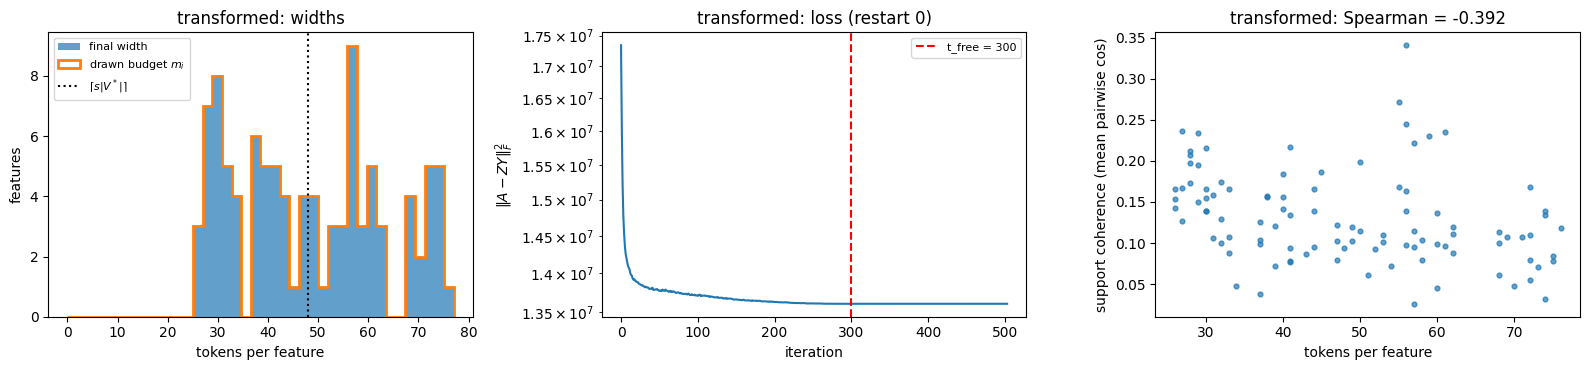

[transformed] width: min=26  median=47  max=76  total=4800   coherence: median=0.120   Spearman(width, coherence) = -0.392


,feature,width,coherence,top tokens
0,55,76,0.118576,"▁size, ▁rate, ▁length, ▁scale, ▁number, ▁range, ▁level, ▁distance"
1,44,75,0.078364,"▁young, Young, ▁Young, ▁age, ▁youth, ▁Age, ▁aged, ▁children"
2,85,75,0.084734,"▁organisation, ▁organisations, organisation, ▁organised, ▁organization, isation, ▁civilisation, isations"
3,6,74,0.139139,"▁usually, ▁generally, ▁largely, ▁mostly, ▁often, ▁mainly, ▁primarily, ▁rarely"
4,71,74,0.032048,"▁himself, ▁him, ▁his, ▁he, ▁He, He, His, ▁themselves"
5,60,26,0.142065,"▁both, both, Both, ▁either, ▁respectively, ▁two, Two, ▁duo"
6,75,26,0.165243,"▁citizen, ▁citizens, Citizens, ▁civil, ▁citizenship, ▁Civil, ▁public, ▁civic"
7,88,26,0.153068,"▁trade, ▁trading, ▁commerce, ▁economic, ▁industrial, ▁exchange, ▁economy, ▁business"
8,24,27,0.167259,"▁only, Only, ▁Only, ▁just, ▁sole, ▁Just, ▁lone, ▁alone"
9,25,27,0.126488,"▁a, ▁an, ▁another, a, an, Another, ▁A, An"


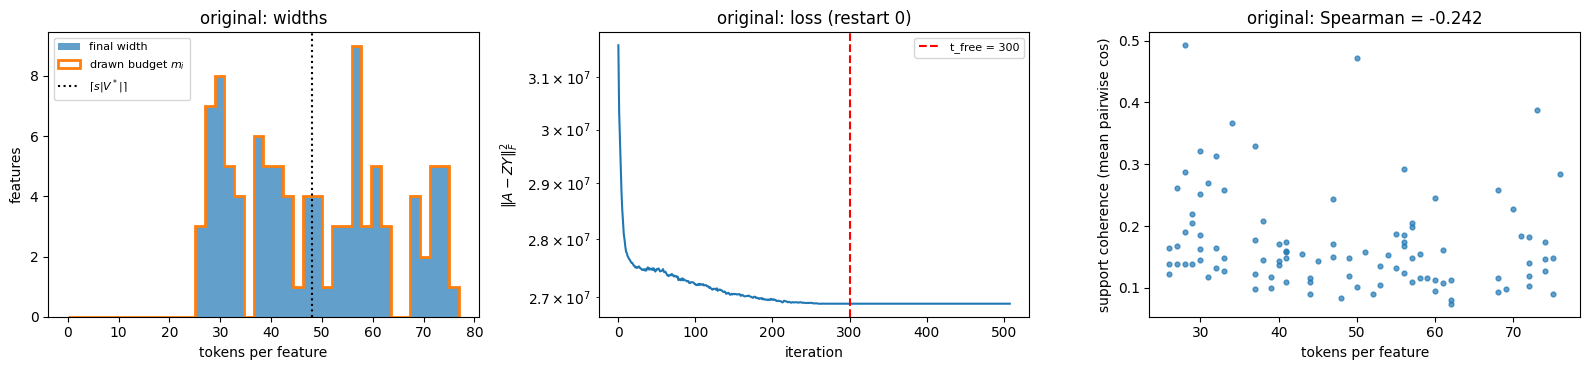

[original] width: min=26  median=47  max=76  total=4800   coherence: median=0.148   Spearman(width, coherence) = -0.242


,feature,width,coherence,top tokens
0,55,76,0.283574,"▁Ireland, ▁Greece, ▁Italy, ▁Spain, ▁Poland, ▁Germany, ▁Egypt, ▁Israel"
1,44,75,0.089936,"▁years, ▁year, ▁months, ▁decades, ▁days, year, ▁age, ▁month"
2,85,75,0.148184,"▁vote, ▁voting, ▁parliament, ▁elections, ▁Parliament, ▁Senate, ▁parliamentary, ▁senate"
3,6,74,0.126605,"▁voting, ▁trading, ▁drinking, ▁cooking, ▁shooting, ▁reading, Voting, ▁dancing"
4,71,74,0.174643,"▁organisation, ▁organised, ▁organisations, organisation, ▁civilisation, alised, ▁recognised, isation"
5,60,26,0.164784,"▁civil, ▁culture, ▁Civil, ▁Culture, ▁cultural, ▁social, ▁citizen, ▁Social"
6,75,26,0.121738,"▁part, ▁parts, ▁Part, ▁portion, ▁par, ▁piece, ▁pieces, ▁Par"
7,88,26,0.138296,"▁experienced, ▁experience, ▁professional, ▁Experience, ▁Professional, ▁skilled, ▁professionals, ▁inexperienced"
8,24,27,0.137840,"▁complex, ▁complicated, ▁complexity, ▁complexes, ▁sophisticated, ▁difficult, ▁simple, ▁ambitious"
9,25,27,0.261627,"▁can, can, ▁Can, Can, ▁could, ▁may, ▁will, ▁would"


In [14]:
import matplotlib.pyplot as plt


def support_coherence(Y_: torch.Tensor, rows: torch.Tensor) -> np.ndarray:
    """Mean pairwise cosine of each feature's support rows: (||sum u||^2 - m) / (m (m - 1)) with u the unit rows."""
    U = F.normalize(rows.float().cpu(), dim=1)
    out = np.full(Y_.shape[0], np.nan)
    for i in range(Y_.shape[0]):
        sup = torch.nonzero(Y_[i]).flatten()
        m = len(sup)
        if m >= 2:
            s = U[sup].sum(0)
            out[i] = ((s @ s).item() - m) / (m * (m - 1))
    return out


def width_report(name: str, fit_out: dict, Y_: torch.Tensor, rows: torch.Tensor) -> pd.DataFrame:
    """Width histogram, loss curve and width-vs-coherence scatter of one fit; returns the per-feature table."""
    width = (Y_ != 0).sum(1).numpy()
    coh = support_coherence(Y_, rows)
    df = pd.DataFrame({"feature": np.arange(len(width)), "width": width, "coherence": coh})
    ok = np.isfinite(coh)
    rs = df.loc[ok, "width"].corr(df.loc[ok, "coherence"], method="spearman") if ok.sum() > 2 else float("nan")

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    drawn = fit_out.get("budgets_drawn")
    hi = max(width.max(), drawn.max().item() if drawn is not None else 0) + 1
    bins = np.linspace(0, hi, min(40, int(hi)) + 1)
    ax[0].hist(width, bins=bins, alpha=0.7, label="final width")
    if drawn is not None:
        ax[0].hist(drawn.numpy(), bins=bins, histtype="step", lw=2, label="drawn budget $m_i$")
    ax[0].axvline(math.ceil(SPARSITY * len(vstar_ids)), color="k", ls=":", label=r"$\lceil s|V^*|\rceil$")
    ax[0].set(xlabel="tokens per feature", ylabel="features", title=f"{name}: widths")
    ax[0].legend(fontsize=8)
    ax[1].semilogy(fit_out["loss_history"])
    ax[1].axvline(fit_out["t_free"], color="r", ls="--", label=f"t_free = {fit_out['t_free']}")
    ax[1].set(xlabel="iteration", ylabel=r"$\|A - ZY\|_F^2$", title=f"{name}: loss (restart {fit_out['best_restart']})")
    ax[1].legend(fontsize=8)
    ax[2].scatter(width, coh, s=12, alpha=0.7)
    ax[2].set(xlabel="tokens per feature", ylabel="support coherence (mean pairwise cos)",
              title=f"{name}: Spearman = {rs:.3f}")
    plt.tight_layout()
    plt.show()

    print(f"[{name}] width: min={width.min()}  median={np.median(width):.0f}  max={width.max()}  total={width.sum()}   "
          f"coherence: median={np.nanmedian(coh):.3f}   Spearman(width, coherence) = {rs:.3f}")
    ext = pd.concat([df.nlargest(5, "width"), df.nsmallest(5, "width")])
    ext["top tokens"] = [", ".join(tokenizer.convert_ids_to_tokens(
        [vstar_ids[j] for j in torch.argsort(Y_[f].abs(), descending=True)[:8].tolist()])) for f in ext["feature"]]
    display(ext.reset_index(drop=True))
    return df


width_df = width_report("transformed", fit_out, Y, E_X)
width_df0 = width_report("original", fit0_out, Y0, E_vstar_orig)


### 3.1.f Baseline: truncated SVD with the same $k$

The rank-$k$ truncated SVD $A_k = U_k \Sigma_k V_k^\top$ is the best possible rank-$k$ approximation
(Eckart–Young theorem), so no rank-$k$ factorization can have a lower error, including Sparse MF.
The gap between the two errors is what the WTA sparsity costs in reconstruction.

In [15]:
for name, A_mat, err, mask, Z_mat in [("transformed", A_cpu, rel_err, nz, Z), ("original", A0_cpu, rel_err0, nz0, Z0)]:
    U, S, Vh = torch.linalg.svd(A_mat, full_matrices=False)
    A_svd = U[:, :RANK] @ torch.diag(S[:RANK]) @ Vh[:RANK]
    svd_rel_err = (torch.norm(A_mat - A_svd) / torch.norm(A_mat)).item()

    svd_nnz = U[:, :RANK].numel() + RANK + Vh[:RANK].numel()
    smf_nnz = Z_mat.numel() + int(mask.sum())
    print(f"[{name}] rank-{RANK} truncated SVD : relative error = {svd_rel_err:.4f}   (parameters: {svd_nnz:,})")
    print(f"[{name}] rank-{RANK} Sparse MF     : relative error = {err:.4f}   (nonzero parameters: {smf_nnz:,})")

    # Smallest SVD rank whose error is no worse than Sparse MF's.
    tail = torch.sqrt(torch.flip(torch.cumsum(torch.flip(S ** 2, [0]), 0), [0]) / (S ** 2).sum())
    matching_rank = int((tail <= err).nonzero()[0]) if (tail <= err).any() else len(S)
    print(f"[{name}] SVD reaches the Sparse MF error ({err:.4f}) at rank {matching_rank}\n")
del U, S, Vh, A_svd

[transformed] rank-100 truncated SVD : relative error = 0.8122   (parameters: 706,500)
[transformed] rank-100 Sparse MF     : relative error = 0.8752   (nonzero parameters: 235,200)
[transformed] SVD reaches the Sparse MF error (0.8752) at rank 47

[original] rank-100 truncated SVD : relative error = 0.8177   (parameters: 706,500)
[original] rank-100 Sparse MF     : relative error = 0.9149   (nonzero parameters: 235,200)
[original] SVD reaches the Sparse MF error (0.9149) at rank 4



---
# Step 3.2: Identifying concept-related features

Most of the $k$ features are general (punctuation, function words, and so on). The selection runs in two filters:

1. **Mass ratio** $\rho_i$: is feature $i$ used mostly by concept tokens rather than neutral tokens? Keep the feature if $\rho_i \ge \tau = 2.0$.
2. **LLM judge** (Gemini, two stages): describe the feature's tokens *without* seeing the concept name,
   then ask whether that description is the concept. Keep the feature if `is_member` is true and confidence ≥ 0.85.

The features that pass both filters form $F_C$.

### 3.2.a Label every token in $V^*$

$\ell_t \in$ {concept, neutral, both}, depending on whether $t$ appears in $S_C$ only, $S_N$ only, or both.
Codes: `1` = concept, `0` = neutral, `2` = both.

In [16]:
token_to_code = build_token_label_codes(CONCEPT, dataset, tokenizer)
codes = np.array([token_to_code.get(t, 0) for t in vstar_ids])

print(f"T_C (concept-only) = {(codes == 1).sum()}   T_N (neutral-only) = {(codes == 0).sum()}   "
      f"both = {(codes == 2).sum()}")

T_C (concept-only) = 1850   T_N (neutral-only) = 2312   both = 598


### 3.2.b Score features by mass ratio and keep $\rho_i \ge \tau$

As implemented in `compute_embedding_stats` (column `ratio_abs`):

$$\rho_i = \frac{\operatorname{mean}_{t\in T_C} |Y_{i,t}|}{\operatorname{mean}_{t\in T_N} |Y_{i,t}|}$$

Tokens labeled *both* are excluded from the ratio. The threshold sweep below is the per-concept view of
Figure 6 in the paper.

In [17]:
stats = compute_embedding_stats(Y.T, vstar_ids, token_to_code, CONCEPT).sort_values("ratio_abs", ascending=False)

for thr in [1.0, 1.25, 1.5, 1.75, 2.0, 2.25]:
    print(f"rho >= {thr:<4}: {(stats['ratio_abs'] >= thr).sum():3d} / {RANK} features")

candidates = stats[stats["ratio_abs"] >= TAU]
print(f"\n{len(candidates)} candidate features pass tau = {TAU}")
candidates[["feature", "ratio_abs", "mean_abs_concept", "mean_abs_neutral", "num_concept", "num_neutral", "num_both"]]

rho >= 1.0 :  81 / 100 features
rho >= 1.25:  75 / 100 features
rho >= 1.5 :  68 / 100 features
rho >= 1.75:  58 / 100 features
rho >= 2.0 :  51 / 100 features
rho >= 2.25:  44 / 100 features

51 candidate features pass tau = 2.0


,feature,ratio_abs,mean_abs_concept,mean_abs_neutral,num_concept,num_neutral,num_both
15,15,29.577017,0.003362,0.000114,49,3,4
70,70,9.545409,0.002123,0.000222,38,7,8
88,88,8.624207,0.002262,0.000262,22,4,0
93,93,7.800671,0.002635,0.000338,38,7,5
75,75,7.543005,0.001690,0.000224,15,4,7
80,80,7.446170,0.002989,0.000401,43,10,4
34,34,6.826538,0.002763,0.000405,44,10,2
39,39,5.956012,0.001277,0.000214,19,9,19
73,73,5.682971,0.000897,0.000158,14,3,12
45,45,5.403991,0.001832,0.000339,33,12,23


### 3.2.c Collect the tokens the judge will see

For each candidate, the code takes the tokens with nonzero $Y_{i,t}$, sorted by $|Y_{i,t}|$, and keeps the top 20.
The paper text says "concept-labeled tokens", but the released code sends the top activating tokens
whatever their label. This notebook follows the code. The `labels` column shows each token's label.

In [18]:
token_label_map = {tid: "both" if c == 2 else CONCEPT if c == 1 else "Neutral" for tid, c in token_to_code.items()}
feature_rows = collect_feature_rows_for_embeddings(
    Y.T, vstar_ids, token_label_map, tl_model, _safe_model_name(MODEL_NAME), CONCEPT, RANK,
)
feat_tokens = pd.DataFrame(feature_rows).set_index("feature")[["activating_tokens", "labels"]]

cand = candidates[["feature", "ratio_abs"]].join(feat_tokens, on="feature").reset_index(drop=True)
if SMOKE:
    cand = cand.head(3)  # smoke: judge only the 3 highest-rho candidates
cand["judge_tokens"] = cand["activating_tokens"].apply(lambda toks: toks[:TOP_K_TOKENS])
cand[["feature", "ratio_abs", "judge_tokens"]]

,feature,ratio_abs,judge_tokens
0,15,29.577017,"[ Roman, Rome, Romans, Roman, Rome, Romans, Roma, Romana, Rom, Caesar, Tiberius, Etrus, Caesar, Greek, Hadrian, Nero, Tacitus, Aene, Italy, Greece]"
1,70,9.545409,"[ less, fewer, less, lesser, more, greater, richer, poorer, least, larger, longer, wider, reduced, rich, broader, diminished, poor, rich, increased, than]"
2,88,8.624207,"[ trade, trading, commerce, economic, industrial, exchange, economy, business, markets, industrial, Exchange, Economic, industries, mercantile, businesses, economical, marketplaces,..."
3,93,7.800671,"[ leadership, lead, led, leader, command, commanded, leaders, leads, leading, commands, dominance, dominated, Command, dominate, dominant, led, control, controlled, commander, ru..."
4,75,7.543005,"[ citizen, citizens, Citizens, civil, citizenship, Civil, public, civic, social, society, civilians, population, Social, societies, inhabitants, people, peoples, populations, civi..."
5,80,7.446170,"[ defeat, defeated, victory, defeating, victories, conquered, triumph, conquest, successful, invaded, succeeded, succeed, conquests, invasion, killed, assassinated, murdered, inva..."
6,34,6.826538,"[ king, emperor, King, kings, Emperor, King, emperors, queen, Queen, Emper, empire, Empire, emper, empires, monarchs, imperial, kingdoms, monarchy, prince, Empires]"
7,39,5.956012,"[ also, also, additionally, Additionally, another, Another, other, further, Other, Others, again, ditionally, too, others, still, even, however, addition, same, along]"
8,73,5.682971,"[ due, Due, because, since, Because, since, Since, cause, virtue, based, given, resulting, based, according, compared, depending, attributed, reasons, resulted, duo]"
9,45,5.403991,"[ probably, possibly, perhaps, probably, may, sometimes, possible, often, could, usually, either, some, necessarily, or, allegedly, even, Some, May, supposed, would]"


### 3.2.d-0 Rate-limited Gemini client

The free tier allows **15 requests per minute per model**. Stage 1 and Stage 2 make one request per
candidate each, so 2 × (number of candidates) requests in total. This wrapper does three things:

- spaces requests at least `60 / RPM` seconds apart (with a 10% margin);
- on a per-minute 429, waits the `retry in Ns` delay the server reports, then retries;
- fails immediately on a *daily* quota error, because waiting would not help.

Answers are cached in `descriptions` and `verdicts`. Re-running a stage only queries the features that
are still missing, so a crash never wastes quota you already spent.

In [19]:
import re
import time

GEMINI_RPM = 15


class ThrottledGemini:
    def __init__(self, inner: SimpleGeminiClient, rpm: int = GEMINI_RPM, max_attempts: int = 6):
        inner.max_retries = 1  # retries are handled here, with the server's retry delay
        self.inner = inner
        self.interval = 60.0 / rpm * 1.1
        self.max_attempts = max_attempts
        self._last = 0.0

    def generate(self, prompt: str) -> str:
        for attempt in range(self.max_attempts):
            time.sleep(max(0.0, self._last + self.interval - time.monotonic()))
            self._last = time.monotonic()
            try:
                return self.inner.generate(prompt)
            except RuntimeError as e:
                msg = str(e)
                if "429" not in msg or "PerDay" in msg or attempt == self.max_attempts - 1:
                    raise
                m = re.search(r"retry in ([\d.]+)s", msg)
                time.sleep(float(m.group(1)) + 1 if m else 60)


USE_THROTTLE = False  # billing enabled; set True to go back to free-tier pacing

if USE_THROTTLE:
    client = ThrottledGemini(SimpleGeminiClient(model_name=GEMINI_MODEL))
else:
    client = SimpleGeminiClient(model_name=GEMINI_MODEL)

# Persisted in RUN_DIR/judge.json, saved after every Gemini call, so a restart re-queries nothing.
# 3.1.d moves judge.json aside whenever it re-fits.
JUDGE_PATH = RUN_DIR / "judge.json"
_judge = load_json(JUDGE_PATH, {})
descriptions = {int(f): d for f, d in _judge.get("descriptions", {}).items()}
verdicts = {int(f): tuple(v) for f, v in _judge.get("verdicts", {}).items()}


def save_judge() -> None:
    save_json(JUDGE_PATH, {"descriptions": descriptions, "verdicts": verdicts})

print(f"{2 * len(cand)} requests needed, {len(descriptions)} descriptions and {len(verdicts)} verdicts cached; "
      f"throttle={'on' if USE_THROTTLE else 'off'}")

102 requests needed, 0 descriptions and 0 verdicts cached; throttle=off


### 3.2.d LLM judge, stage 1: describe each feature *without* the concept name

Stage 1 never sees the concept name. This avoids confirmation bias, where tokens like *wizard* could
look like "Harry Potter" just because the judge was told the concept.

In [20]:
print("---- Stage 1 prompt ----")
print(TOKENS_DESC_SYS.strip(), "\n\nTokens: {tokens}\nExplanation of feature behavior:")

todo = cand[~cand["feature"].astype(int).isin(descriptions)]
for _, row in tqdm(todo.iterrows(), total=len(todo), desc="Stage 1: describe"):
    descriptions[int(row["feature"])] = get_description(client, row["judge_tokens"])
    save_judge()
cand["description"] = cand["feature"].map(descriptions)
cand[["feature", "ratio_abs", "description"]]

---- Stage 1 prompt ----
You get tokens that represent a single feature vector (with some noise).
Infer the single most specific, cohesive concept shared by the relevant tokens.
Return only one concise sentence. No preface, no list, no caveats.

Example:
Tokens: ['▁tomorrow','▁tonight','▁yesterday','▁today','▁demain']
Explanation of feature behavior: this vector is related to specific dates and times (e.g., today/tomorrow/yesterday). 

Tokens: {tokens}
Explanation of feature behavior:


Stage 1: describe: 100%|██████████| 51/51 [00:41<00:00,  1.22it/s]


,feature,ratio_abs,description
0,15,29.577017,"This feature vector represents concepts, figures, and locations associated with ancient Rome and Greco-Roman antiquity."
1,70,9.545409,"This vector represents comparative and quantitative adjectives and modifiers related to scale, degree, and amount."
2,88,8.624207,"This feature vector represents the concepts of commerce, trade, and economic activity."
3,93,7.800671,"This vector represents the concept of exercising authority, guidance, and control."
4,75,7.543005,"This vector represents the concept of community, society, and the collective population of citizens."
5,80,7.446170,"This vector represents the concept of military conflict, conquest, and success or failure in battle."
6,34,6.826538,"This vector represents royalty, monarchy, and imperial power structures."
7,39,5.956012,"This vector represents additive, supplementary, or incremental transitions and relationships."
8,73,5.682971,"This vector represents causal relationships, rationales, and logical dependencies."
9,45,5.403991,"These tokens represent epistemic modality and expressions of probability, uncertainty, or qualification."


In [21]:
N_SHOW = 10
LABEL_TAG = {1: "C", 0: "N", 2: "B"}  # concept / neutral / both

for _, row in cand.sort_values("ratio_abs", ascending=False).iterrows():
    feat = int(row["feature"])
    mags = Y[feat].abs()
    top = torch.argsort(mags, descending=True)[:N_SHOW]
    top = top[mags[top] > 0].tolist()
    toks = tokenizer.convert_ids_to_tokens([vstar_ids[j] for j in top])

    print(f"=== feature {feat}  rho={row['ratio_abs']:.2f} ===")
    print(f"  Gemini : {descriptions.get(feat, '<not described yet>')}")
    print("  tokens : " + ", ".join(f"{t!r}[{LABEL_TAG[codes[j]]}] {mags[j]:.2f}" for t, j in zip(toks, top)))
    print()

=== feature 15  rho=29.58 ===
  Gemini : This feature vector represents concepts, figures, and locations associated with ancient Rome and Greco-Roman antiquity.
  tokens : '▁Roman'[C] 0.29, '▁Rome'[C] 0.28, '▁Romans'[C] 0.26, 'Roman'[C] 0.26, 'Rome'[C] 0.24, 'Romans'[C] 0.20, '▁Roma'[C] 0.18, '▁Romana'[C] 0.17, '▁Rom'[C] 0.17, '▁Caesar'[C] 0.16

=== feature 70  rho=9.55 ===
  Gemini : This vector represents comparative and quantitative adjectives and modifiers related to scale, degree, and amount.
  tokens : '▁less'[B] 0.41, '▁fewer'[C] 0.34, 'less'[C] 0.34, '▁lesser'[C] 0.29, '▁more'[B] 0.23, '▁greater'[C] 0.22, '▁richer'[C] 0.22, '▁poorer'[C] 0.22, '▁least'[B] 0.19, '▁larger'[B] 0.15

=== feature 88  rho=8.62 ===
  Gemini : This feature vector represents the concepts of commerce, trade, and economic activity.
  tokens : '▁trade'[C] 0.37, '▁trading'[C] 0.32, '▁commerce'[C] 0.26, '▁economic'[C] 0.26, '▁industrial'[C] 0.24, '▁exchange'[C] 0.23, '▁economy'[C] 0.22, '▁business'[N] 0.21, '

### 3.2.e LLM judge, stage 2: is the description *the* concept?

Stage 2 sees only the concept name and the Stage 1 description. It returns `{"is_member", "confidence"}`.
A feature joins $F_C$ only if `is_member` is true **and** confidence ≥ 0.85.

In [22]:
print("---- Stage 2 prompt ----")
print(MEMBERSHIP_PROMPT.format(concept=CONCEPT, desc="{description}").strip())

todo = {f: descriptions[f] for f in cand["feature"].astype(int).tolist() if f in descriptions and f not in verdicts}
for feat, desc in tqdm(todo.items(), desc="Stage 2: classify"):
    verdicts[feat] = classify_membership_with_desc(client, CONCEPT, desc)
    save_judge()

cand["is_member"] = cand["feature"].map(lambda f: verdicts[int(f)][0])
cand["confidence"] = pd.to_numeric(cand["feature"].map(lambda f: verdicts[int(f)][1]), errors="coerce").fillna(0.0)
cand["selected"] = (cand["is_member"] == True) & (cand["confidence"] >= CONFIDENCE)

F_C = sorted(cand.loc[cand["selected"], "feature"].astype(int).tolist())
print(f"\nF_C = {F_C}  ({len(F_C)} concept-related features)")
cand[["feature", "ratio_abs", "is_member", "confidence", "selected", "description"]]

---- Stage 2 prompt ----
You get a concept name and a feature's description.
Decide if this feature describes the given concept. Consider if the feature is DISTINCTIVE for the concept (not broad like "sport" for "basketball") and not too noisy.
A feature should be marked true only if the concept is central and dominant in the description, not just one of several themes.
Return ONLY JSON: {"is_member": true|false, "confidence": 0..1}

Example 1:
Concept: Charity
Description: This vector represents elements related to giving and donations to charitable causes.
Answer: {"is_member": true, "confidence": 0.98}

Example 2:
Concept: Charity
Description: This vector represents elements related to money, such as gambling, investing and charity.
Answer: {"is_member": false, "confidence": 0.80}

Concept: Ancient Rome
Description: {description}
Answer:


Stage 2: classify: 100%|██████████| 51/51 [00:42<00:00,  1.21it/s]


F_C = [15]  (1 concept-related features)


,feature,ratio_abs,is_member,confidence,selected,description
0,15,29.577017,True,0.99,True,"This feature vector represents concepts, figures, and locations associated with ancient Rome and Greco-Roman antiquity."
1,70,9.545409,False,1.00,False,"This vector represents comparative and quantitative adjectives and modifiers related to scale, degree, and amount."
2,88,8.624207,False,0.95,False,"This feature vector represents the concepts of commerce, trade, and economic activity."
3,93,7.800671,False,0.95,False,"This vector represents the concept of exercising authority, guidance, and control."
4,75,7.543005,False,0.95,False,"This vector represents the concept of community, society, and the collective population of citizens."
5,80,7.446170,False,0.90,False,"This vector represents the concept of military conflict, conquest, and success or failure in battle."
6,34,6.826538,False,0.85,False,"This vector represents royalty, monarchy, and imperial power structures."
7,39,5.956012,False,0.99,False,"This vector represents additive, supplementary, or incremental transitions and relationships."
8,73,5.682971,False,0.99,False,"This vector represents causal relationships, rationales, and logical dependencies."
9,45,5.403991,False,1.00,False,"These tokens represent epistemic modality and expressions of probability, uncertainty, or qualification."


### 3.2.e″ Width and coherence of the concept features (varnnz)

Are the selected features unusually wide or narrow? The table puts each $F_C$ feature's width, support coherence (3.1.e″) and
mass ratio $\rho_i$ (`ratio_abs`, 3.2.b) next to the median over the other features (`width pct` = percentile among all $k$).
The scatter shows $\rho_i$ vs. width for every feature, with $F_C$ highlighted and $\tau$ dashed. Transformed fit (`width_df`).

,feature,width,width pct,coherence,ratio_abs
0,15,56.0,0.66,0.138867,29.577017
1,rest (median of 99),47.0,0.50,0.119518,2.089016


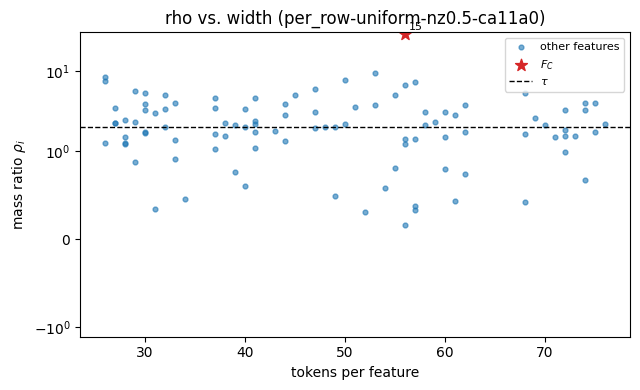

In [23]:
fc_df = width_df.merge(stats[["feature", "ratio_abs"]], on="feature")
fc_df["width pct"] = fc_df["width"].rank(pct=True)
fc_df["in F_C"] = fc_df["feature"].isin(F_C)
fc, rest = fc_df[fc_df["in F_C"]], fc_df[~fc_df["in F_C"]]
cmp = pd.concat([
    fc[["feature", "width", "width pct", "coherence", "ratio_abs"]].assign(feature=fc["feature"].astype(str)),
    pd.DataFrame([{"feature": f"rest (median of {len(rest)})", "width": rest["width"].median(),
                   "width pct": rest["width pct"].median(), "coherence": rest["coherence"].median(),
                   "ratio_abs": rest["ratio_abs"].median()}]),
], ignore_index=True)
display(cmp)

rho_plot = fc_df["ratio_abs"].where(np.isfinite(fc_df["ratio_abs"]))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(rest["width"], rho_plot[~fc_df["in F_C"]], s=12, alpha=0.6, label="other features")
ax.scatter(fc["width"], rho_plot[fc_df["in F_C"]], s=80, marker="*", color="C3", label="$F_C$")
for _, r in fc.iterrows():
    ax.annotate(str(int(r["feature"])), (r["width"], rho_plot[r.name]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(TAU, color="k", ls="--", lw=1, label=r"$\tau$")
ax.set_yscale("symlog", linthresh=1)
ax.set(xlabel="tokens per feature", ylabel=r"mass ratio $\rho_i$", title=f"rho vs. width ({SPARSITY_CFG.slug()})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 3.2.e′ Same selection on the original fit → $F_{C0}$

The mass ratio ($\tau$) and the two-stage judge (same client, prompts and thresholds) applied to `Y0`, so the concept directions of
both fits are known. Answers are cached in `ORIG_DIR/judge0.json` (saved after every call), shared by all configurations.
The main flow (3.2.f and Step 3.3) uses the transformed fit's $F_C$. The last line lists $|\cos(\tilde{\mathbf z}_i, \tilde{\mathbf m})|$ for $i\in F_C$.

In [24]:
# tau filter + 2-stage judge on the original fit (Y0); cached in ORIG_DIR/judge0.json.
JUDGE0_PATH = ORIG_DIR / "judge0.json"
_judge0 = load_json(JUDGE0_PATH, {})
descriptions0 = {int(f): d for f, d in _judge0.get("descriptions", {}).items()}
verdicts0 = {int(f): tuple(v) for f, v in _judge0.get("verdicts", {}).items()}


def save_judge0() -> None:
    save_json(JUDGE0_PATH, {"descriptions": descriptions0, "verdicts": verdicts0})


stats0 = compute_embedding_stats(Y0.T, vstar_ids, token_to_code, CONCEPT).sort_values("ratio_abs", ascending=False)
feat_tokens0 = pd.DataFrame(collect_feature_rows_for_embeddings(
    Y0.T, vstar_ids, token_label_map, tl_model, _safe_model_name(MODEL_NAME), CONCEPT, RANK,
)).set_index("feature")[["activating_tokens", "labels"]]
cand0 = stats0[stats0["ratio_abs"] >= TAU][["feature", "ratio_abs"]].join(feat_tokens0, on="feature").reset_index(drop=True)
if SMOKE:
    cand0 = cand0.head(3)  # smoke: judge only the 3 highest-rho candidates

for _, row in tqdm(cand0.iterrows(), total=len(cand0), desc="original fit: judge"):
    f = int(row["feature"])
    if f not in descriptions0:
        descriptions0[f] = get_description(client, row["activating_tokens"][:TOP_K_TOKENS])
        save_judge0()
    if f not in verdicts0:
        verdicts0[f] = classify_membership_with_desc(client, CONCEPT, descriptions0[f])
        save_judge0()

cand0["description"] = cand0["feature"].map(lambda f: descriptions0[int(f)])
cand0["is_member"] = cand0["feature"].map(lambda f: verdicts0[int(f)][0])
cand0["confidence"] = pd.to_numeric(cand0["feature"].map(lambda f: verdicts0[int(f)][1]), errors="coerce").fillna(0.0)
cand0["selected"] = (cand0["is_member"] == True) & (cand0["confidence"] >= CONFIDENCE)

F_C0 = sorted(cand0.loc[cand0["selected"], "feature"].astype(int).tolist())
print(f"original fit: {len(cand0)} candidates pass tau = {TAU}  ->  F_C0 = {F_C0}   (transformed fit: F_C = {F_C})")
print("|cos(z~_i, m_X)| for i in F_C: " + (", ".join(
    f"{f}: {cos_m[f]:.3f} (rank {cos_m_order.index(f) + 1}/{RANK})" for f in F_C) or "F_C is empty"))
cand0[["feature", "ratio_abs", "is_member", "confidence", "selected", "description"]]

original fit: judge: 100%|██████████| 40/40 [01:00<00:00,  1.50s/it]

original fit: 40 candidates pass tau = 2.0  ->  F_C0 = [3]   (transformed fit: F_C = [15])
|cos(z~_i, m_X)| for i in F_C: 15: 0.139 (rank 85/100)


,feature,ratio_abs,is_member,confidence,selected,description
0,32,22.342494,False,1.00,False,"Adverbs of frequency, probability, and degree modifying the likelihood or extent of an action or state."
1,3,8.085024,True,0.98,True,"This vector activates on historical places, figures, and concepts from classical antiquity and the Roman Empire."
2,47,7.771883,False,0.99,False,"This vector represents the concept of change, specifically the increase, decrease, or loss of a quantity or state."
3,45,7.630656,False,0.95,False,"This vector represents the concept of territorial control, political power, and the assertion or resistance of dominance over others."
4,95,7.222657,False,1.00,False,"This vector represents common word endings or substrings ending with the letters ""-ian"" and ""-ia""."
5,30,6.388367,False,0.85,False,"This feature activates on words related to rulers, monarchies, and imperial governance or titles."
6,68,5.425524,False,0.95,False,"This vector represents physical locations, establishments, and organized human communities or institutions."
7,60,4.871989,False,0.95,False,"This vector represents concepts related to human society, culture, and civic life."
8,64,4.293042,False,0.90,False,"These tokens represent Latin-derived masculine second-declension noun and adjective suffixes, particularly common in names and classical terminology."
9,99,3.637826,False,1.00,False,This vector represents past-tense action verbs in English.


In [25]:
is_true = cand["is_member"] == True
ordered = cand.assign(
    _group=(~is_true).astype(int),
    _key=np.where(is_true, -cand["confidence"], cand["confidence"]),
).sort_values(["_group", "_key"])

for _, row in ordered.iterrows():
    feat = int(row["feature"])
    mags = Y[feat].abs()
    top = torch.argsort(mags, descending=True)[:N_SHOW]
    top = top[mags[top] > 0].tolist()
    toks = tokenizer.convert_ids_to_tokens([vstar_ids[j] for j in top])

    is_member, conf = verdicts.get(feat, (None, None))
    verdict = "<not classified yet>" if feat not in verdicts else (
        f"is_member={is_member}  confidence={conf if conf is not None else 'n/a'}  "
        f"-> {'SELECTED' if row['selected'] else 'rejected'}"
    )

    print(f"=== feature {feat}  rho={row['ratio_abs']:.2f} ===")
    print(f"  Gemini  : {descriptions.get(feat, '<not described yet>')}")
    print(f"  verdict : {verdict}")
    print("  tokens  : " + ", ".join(f"{t!r}[{LABEL_TAG[codes[j]]}] {mags[j]:.2f}" for t, j in zip(toks, top)))
    print()

=== feature 15  rho=29.58 ===
  Gemini  : This feature vector represents concepts, figures, and locations associated with ancient Rome and Greco-Roman antiquity.
  verdict : is_member=True  confidence=0.99  -> SELECTED
  tokens  : '▁Roman'[C] 0.29, '▁Rome'[C] 0.28, '▁Romans'[C] 0.26, 'Roman'[C] 0.26, 'Rome'[C] 0.24, 'Romans'[C] 0.20, '▁Roma'[C] 0.18, '▁Romana'[C] 0.17, '▁Rom'[C] 0.17, '▁Caesar'[C] 0.16

=== feature 34  rho=6.83 ===
  Gemini  : This vector represents royalty, monarchy, and imperial power structures.
  verdict : is_member=False  confidence=0.85  -> rejected
  tokens  : '▁king'[C] 0.27, '▁emperor'[C] 0.26, '▁King'[C] 0.25, '▁kings'[C] 0.23, '▁Emperor'[C] 0.23, 'King'[N] 0.23, '▁emperors'[C] 0.22, '▁queen'[C] 0.22, '▁Queen'[N] 0.21, '▁Emper'[C] 0.19

=== feature 80  rho=7.45 ===
  Gemini  : This vector represents the concept of military conflict, conquest, and success or failure in battle.
  verdict : is_member=False  confidence=0.9  -> rejected
  tokens  : '▁defeat'[C] 0.

In [26]:
members = cand[cand["is_member"] == True].sort_values("ratio_abs", ascending=False)
print(f"{len(members)} / {len(cand)} candidates have is_member=True\n")

for _, row in members.iterrows():
    feat = int(row["feature"])
    mags = Y[feat].abs()
    top = torch.argsort(mags, descending=True)[:N_SHOW]
    top = top[mags[top] > 0].tolist()
    toks = tokenizer.convert_ids_to_tokens([vstar_ids[j] for j in top])

    print(f"=== feature {feat}  rho={row['ratio_abs']:.2f} ===")
    print(f"  Gemini  : {row['description']}")
    print(f"  verdict : confidence={row['confidence']:.2f}  -> {'SELECTED' if row['selected'] else 'rejected (confidence < ' + str(CONFIDENCE) + ')'}")
    print("  tokens  : " + ", ".join(f"{t!r}[{LABEL_TAG[codes[j]]}] {mags[j]:.2f}" for t, j in zip(toks, top)))
    print()

1 / 51 candidates have is_member=True

=== feature 15  rho=29.58 ===
  Gemini  : This feature vector represents concepts, figures, and locations associated with ancient Rome and Greco-Roman antiquity.
  verdict : confidence=0.99  -> SELECTED
  tokens  : '▁Roman'[C] 0.29, '▁Rome'[C] 0.28, '▁Romans'[C] 0.26, 'Roman'[C] 0.26, 'Rome'[C] 0.24, 'Romans'[C] 0.20, '▁Roma'[C] 0.18, '▁Romana'[C] 0.17, '▁Rom'[C] 0.17, '▁Caesar'[C] 0.16



### 3.2.f Inspect the selected features

Table 3 of the paper reports only 1–3 embedding features per concept (Harry Potter on Gemma: 1).
Each selected feature should be a tight cluster of concept-specific tokens.

In [27]:
if not F_C:
    print("No feature passed both filters: Step 3.3 will be a no-op for this concept.")

for feat in F_C:
    row = cand.loc[cand["feature"] == feat].iloc[0]
    print(f"=== feature {feat}  rho={row['ratio_abs']:.2f}  conf={row['confidence']:.2f} ===")
    print(f"  {row['description']}")
    print("  tokens:", ", ".join(f"{t!r}[{l[0]}]" for t, l in zip(row["activating_tokens"][:30], row["labels"][:30])))
    print()

=== feature 15  rho=29.58  conf=0.99 ===
  This feature vector represents concepts, figures, and locations associated with ancient Rome and Greco-Roman antiquity.
  tokens: ' Roman'[A], ' Rome'[A], ' Romans'[A], 'Roman'[A], 'Rome'[A], 'Romans'[A], ' Roma'[A], ' Romana'[A], ' Rom'[A], ' Caesar'[A], ' Tiberius'[A], ' Etrus'[A], 'Caesar'[A], ' Greek'[A], ' Hadrian'[A], ' Nero'[A], ' Tacitus'[A], ' Aene'[A], ' Italy'[A], ' Greece'[A], ' Lucius'[A], ' Italian'[b], ' Byzantine'[A], ' Cicero'[A], ' Latin'[A], ' Claudius'[A], ' Hellen'[A], ' Julius'[A], 'Nero'[A], ' Tiber'[A]



In [28]:
# One column per selected feature: every token with nonzero Y_{i,t}, sorted by |Y_{i,t}|.
columns = {}
for feat in F_C:
    mags = Y[feat].abs()
    nz_idx = torch.nonzero(mags > 0).flatten()
    nz_idx = nz_idx[torch.argsort(mags[nz_idx], descending=True)].tolist()
    toks = tokenizer.convert_ids_to_tokens([vstar_ids[j] for j in nz_idx])
    columns[f"feature {feat}"] = pd.Series(
        [f"{t} [{LABEL_TAG[codes[j]]}] {mags[j]:.2f}" for t, j in zip(toks, nz_idx)]
    )

wide = pd.DataFrame(columns).fillna("")
wide.index = range(1, len(wide) + 1)

all_cols = sorted({j for feat in F_C for j in torch.nonzero(Y[feat].abs() > 0).flatten().tolist()})
print(f"{len(F_C)} concept features, {len(all_cols)} distinct tokens "
      f"(C={sum(codes[j] == 1 for j in all_cols)}, N={sum(codes[j] == 0 for j in all_cols)}, "
      f"B={sum(codes[j] == 2 for j in all_cols)})")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(wide)

1 concept features, 56 distinct tokens (C=49, N=3, B=4)


,feature 15
1,▁Roman [C] 0.29
2,▁Rome [C] 0.28
3,▁Romans [C] 0.26
4,Roman [C] 0.26
5,Rome [C] 0.24
6,Romans [C] 0.20
7,▁Roma [C] 0.18
8,▁Romana [C] 0.17
9,▁Rom [C] 0.17
10,▁Caesar [C] 0.16


In [29]:
TOP_N = 30
E_ref = E_vstar_X.float().cpu()  # X-space rows = transform(E_vstar): the space Z lives in
token_strs = tokenizer.convert_ids_to_tokens(vstar_ids)

group_masks = {
    "C": codes == 1,
    "C / B": (codes == 1) | (codes == 2),
    "C / B / N": np.ones_like(codes, dtype=bool),
}

for feat in F_C:
    y = Y[feat]
    # z's sign is arbitrary (Y can absorb it); orient it so its support tokens mostly have positive Y.
    sign = 1.0 if y[y != 0].sum() >= 0 else -1.0
    z = sign * Z[:, feat]
    dots = E_ref @ z
    cos = dots / (E_ref.norm(dim=1) * z.norm())

    df = pd.DataFrame({
        "token": token_strs,
        "label": [LABEL_TAG[c] for c in codes],
        "dot": dots.numpy(),
        "cos": cos.numpy(),
        "Y": (sign * y).numpy(),
        "in_support": (y != 0).numpy(),
    })

    print(f"=== feature {feat}   ||z|| = {z.norm():.3f}   sign flipped: {sign < 0} ===")
    for name, mask in group_masks.items():
        top = df[mask].sort_values("dot", ascending=False).head(TOP_N).reset_index(drop=True)
        top.index += 1
        print(f"\n-- {name}: {int(mask.sum())} tokens, top {TOP_N} by <e_t, z> --")
        display(top)

=== feature 15   ||z|| = 189.237   sign flipped: False ===

-- C: 1850 tokens, top 30 by <e_t, z> --


,token,label,dot,cos,Y,in_support
1,▁Roman,C,10414.087891,0.774101,0.292643,True
2,▁Rome,C,9840.731445,0.764705,0.277353,True
3,▁Romans,C,9391.482422,0.715677,0.262813,True
4,Roman,C,9261.165039,0.743406,0.260270,True
5,Rome,C,8571.626953,0.719994,0.241726,True
6,Romans,C,7243.200195,0.602353,0.204751,True
7,▁Roma,C,6211.512207,0.591515,0.177272,True
8,▁Romana,C,6151.506348,0.485423,0.174992,True
9,▁Rom,C,5941.905762,0.546882,0.170978,True
10,▁Caesar,C,5735.194336,0.482561,0.156524,True



-- C / B: 2448 tokens, top 30 by <e_t, z> --


,token,label,dot,cos,Y,in_support
1,▁Roman,C,10414.087891,0.774101,0.292643,True
2,▁Rome,C,9840.731445,0.764705,0.277353,True
3,▁Romans,C,9391.482422,0.715677,0.262813,True
4,Roman,C,9261.165039,0.743406,0.260270,True
5,Rome,C,8571.626953,0.719994,0.241726,True
6,Romans,C,7243.200195,0.602353,0.204751,True
7,▁Roma,C,6211.512207,0.591515,0.177272,True
8,▁Romana,C,6151.506348,0.485423,0.174992,True
9,▁Rom,C,5941.905762,0.546882,0.170978,True
10,▁Caesar,C,5735.194336,0.482561,0.156524,True



-- C / B / N: 4760 tokens, top 30 by <e_t, z> --


,token,label,dot,cos,Y,in_support
1,▁Roman,C,10414.087891,0.774101,0.292643,True
2,▁Rome,C,9840.731445,0.764705,0.277353,True
3,▁Romans,C,9391.482422,0.715677,0.262813,True
4,Roman,C,9261.165039,0.743406,0.260270,True
5,Rome,C,8571.626953,0.719994,0.241726,True
6,Romans,C,7243.200195,0.602353,0.204751,True
7,▁Roma,C,6211.512207,0.591515,0.177272,True
8,▁Romana,C,6151.506348,0.485423,0.174992,True
9,▁Rom,C,5941.905762,0.546882,0.170978,True
10,▁Caesar,C,5735.194336,0.482561,0.156524,True


In [30]:
E_unit = E_ref / E_ref.norm(dim=1, keepdim=True)

for feat in F_C:
    y = Y[feat]
    sign = 1.0 if y[y != 0].sum() >= 0 else -1.0
    z = sign * Z[:, feat]
    dots_unit = E_unit @ z

    df_unit = pd.DataFrame({
        "token": token_strs,
        "label": [LABEL_TAG[c] for c in codes],
        "dot_unit": dots_unit.numpy(),
        "||e_t||": E_ref.norm(dim=1).numpy(),
        "Y": (sign * y).numpy(),
        "in_support": (y != 0).numpy(),
    })

    print(f"=== feature {feat}   ||z|| = {z.norm():.3f}   sign flipped: {sign < 0} ===")
    for name, mask in group_masks.items():
        top = df_unit[mask].sort_values("dot_unit", ascending=False).head(TOP_N).reset_index(drop=True)
        top.index += 1
        print(f"\n-- {name}: {int(mask.sum())} tokens, top {TOP_N} by <e_t / ||e_t||, z> --")
        display(top)

=== feature 15   ||z|| = 189.237   sign flipped: False ===

-- C: 1850 tokens, top 30 by <e_t / ||e_t||, z> --


,token,label,dot_unit,||e_t||,Y,in_support
1,▁Roman,C,146.488495,71.091499,0.292643,True
2,▁Rome,C,144.710327,68.002960,0.277353,True
3,Roman,C,140.679779,65.831528,0.260270,True
4,Rome,C,136.249374,62.911301,0.241726,True
5,▁Romans,C,135.432434,69.344421,0.262813,True
6,Romans,C,113.987427,63.543850,0.204751,True
7,▁Roma,C,111.936523,55.491379,0.177272,True
8,▁Rom,C,103.490257,57.415127,0.170978,True
9,▁Romana,C,91.860001,66.966103,0.174992,True
10,▁Caesar,C,91.318436,62.804352,0.156524,True



-- C / B: 2448 tokens, top 30 by <e_t / ||e_t||, z> --


,token,label,dot_unit,||e_t||,Y,in_support
1,▁Roman,C,146.488495,71.091499,0.292643,True
2,▁Rome,C,144.710327,68.002960,0.277353,True
3,Roman,C,140.679779,65.831528,0.260270,True
4,Rome,C,136.249374,62.911301,0.241726,True
5,▁Romans,C,135.432434,69.344421,0.262813,True
6,Romans,C,113.987427,63.543850,0.204751,True
7,▁Roma,C,111.936523,55.491379,0.177272,True
8,▁Rom,C,103.490257,57.415127,0.170978,True
9,▁Romana,C,91.860001,66.966103,0.174992,True
10,▁Caesar,C,91.318436,62.804352,0.156524,True



-- C / B / N: 4760 tokens, top 30 by <e_t / ||e_t||, z> --


,token,label,dot_unit,||e_t||,Y,in_support
1,▁Roman,C,146.488495,71.091499,0.292643,True
2,▁Rome,C,144.710327,68.002960,0.277353,True
3,Roman,C,140.679779,65.831528,0.260270,True
4,Rome,C,136.249374,62.911301,0.241726,True
5,▁Romans,C,135.432434,69.344421,0.262813,True
6,Romans,C,113.987427,63.543850,0.204751,True
7,▁Roma,C,111.936523,55.491379,0.177272,True
8,▁Rom,C,103.490257,57.415127,0.170978,True
9,▁Romana,C,91.860001,66.966103,0.174992,True
10,▁Caesar,C,91.318436,62.804352,0.156524,True


In [31]:
TOP_K_COUNT = 100

rows = []
for feat in F_C:
    y = Y[feat]
    sign = 1.0 if y[y != 0].sum() >= 0 else -1.0
    z = sign * Z[:, feat]
    rankings = {
        "<e_t, z>": E_ref @ z,
        "<e_t / ||e_t||, z>": E_unit @ z,
    }
    for name, scores in rankings.items():
        top = torch.argsort(scores, descending=True)[:TOP_K_COUNT].numpy()
        rows.append({
            "feature": feat,
            "ranking": name,
            "C": int((codes[top] == 1).sum()),
            "B": int((codes[top] == 2).sum()),
            "N": int((codes[top] == 0).sum()),
            "C in support": int(((codes[top] == 1) & (y[top] != 0).numpy()).sum()),
        })

print(f"Label counts among the top {TOP_K_COUNT} of all {len(vstar_ids)} tokens in V* "
      f"(base rate: C={(codes == 1).mean():.1%}, B={(codes == 2).mean():.1%}, N={(codes == 0).mean():.1%})")
pd.DataFrame(rows)

Label counts among the top 100 of all 4760 tokens in V* (base rate: C=38.9%, B=12.6%, N=48.6%)


,feature,ranking,C,B,N,C in support
0,15,"<e_t, z>",89,4,7,49
1,15,"<e_t / ||e_t||, z>",78,6,16,49


### 3.2.g Extended token set: every sentence of the concept's Wikipedia page, $Z$ fixed
$S_C^{ext} = S_C \cup$ all sentences of the article, $S_N^{ext} = S_N \cup$ as many neutral sentences. The new rows go through the **same** transform $T$ fitted in 3.1.c′ (nothing re-estimated), then only a sparse $Y_{ext}$ is fitted against the frozen X-space $Z$. Groups: C / B / N = label in the original $V^*$ (3.2.a), C\* / B\* / N\* = label on the extended sentences; a token gets the first group it matches in the order C, C\*, B, B\*, N, N\*.

In [32]:
# ---- Extended E*: all sentences of the concept's Wikipedia page, Z from 3.1.d fixed, only a sparse Y_ext refit ----
# S_C^ext = S_C + every sentence of the live English Wikipedia article; S_N^ext = S_N + as many neutral sentences
# (one per page of the local wikimedia/wikipedia sample). The new sentences are cached next to RUN_DIR, so re-runs
# use the same page revision and sample.
# Rows go to X-space with the transform T of 3.1.c' exactly as fitted there (same mu_B, W, S_eta: nothing re-estimated),
# then Y_ext = WTA_m((Z^T Z + lambda I)^{-1} Z^T X_ext^T): the Y-step of 3.1.d with Z frozen and the same lambda;
# feature i keeps its 3.1.d width scaled to the larger set, m_i^ext = round(width_i * |V*_ext| / |V*|).
import random
import sys

from varsparse import topk_per_row

sys.path.insert(0, "experiments/resample_sentences")
from fetch_en_sentences import neutral_sentences, page_paragraphs, split_sentences

EXT_PATH = RUN_DIR.parent / "ext_sentences.json"   # shared by every whitening config of this concept and model
EXT_GROUPS = ["C", "C*", "B", "B*", "N", "N*"]

# 1) sentences
ext = load_json(EXT_PATH, None)
if ext is None:
    canon, revid, paras = page_paragraphs(CONCEPT)
    page_sents = split_sentences(paras)
    ext = {"title": canon, "revid": revid, "concept": page_sents,
           "neutral": [r["sentence"] for r in neutral_sentences(
               Path("experiments/resample_sentences/data/wiki_dump_pages.jsonl"), len(page_sents),
               random.Random(SEED), exclude=set(page_sents))]}
    save_json(EXT_PATH, ext)
ext_concept = list(dict.fromkeys([s for s, lbl in dataset if lbl == CONCEPT] + ext["concept"]))
ext_neutral = list(dict.fromkeys([s for s, lbl in dataset if lbl != CONCEPT] + ext["neutral"]))
print(f"'{ext['title']}' rev {ext['revid']}: {len(ext['concept'])} page sentences, {len(ext['neutral'])} new neutral "
      f"({EXT_PATH})\nS_C^ext = {len(ext_concept)} sentences   S_N^ext = {len(ext_neutral)} sentences")

# 2) extended token set (a superset of V*) and its groups
special_ext = set(tokenizer.all_special_ids)


def token_set(sents):
    return {int(t) for s in sents for t in tokenizer(s, add_special_tokens=False)["input_ids"]} - special_ext


c_ids, n_ids = token_set(ext_concept), token_set(ext_neutral)
vstar_ext = sorted(c_ids | n_ids | set(vstar_ids))
codes_ext = np.array([2 if t in c_ids and t in n_ids else 1 if t in c_ids else 0 for t in vstar_ext])
orig_code = dict(zip(vstar_ids, codes.tolist()))


def ext_group(t: int, c_ext: int) -> str:
    """First match in the order C, C*, B, B*, N, N* (C/B/N: label in V*, starred: label on the extended sentences)."""
    o = orig_code.get(t)
    for g, hit in [("C", o == 1), ("C*", c_ext == 1), ("B", o == 2), ("B*", c_ext == 2), ("N", o == 0), ("N*", c_ext == 0)]:
        if hit:
            return g


groups_ext = np.array([ext_group(t, int(c)) for t, c in zip(vstar_ext, codes_ext)])
print(f"|V*_ext| = {len(vstar_ext)}  (|V*| = {len(vstar_ids)}, {len(vstar_ext) - len(vstar_ids)} new)")
display(pd.Series(groups_ext).value_counts().reindex(EXT_GROUPS).fillna(0).astype(int).rename("tokens").to_frame().T)

# 3) X_ext = T(E_{V*_ext}): the 3.1.c' transform, unchanged
ids_ext = torch.tensor(vstar_ext)
if "E" in globals():
    E_ext = E.index_select(0, ids_ext.to(E.device)).detach().float().cpu()
else:   # after 3.3.a the TL matrix is gone; HF rows x EMB_SCALE are the same space (checked in 3.3.a)
    E_ext = W_orig.index_select(0, ids_ext.to(W_orig.device)).detach().float().cpu() * EMB_SCALE
X_ext = transform(E_ext)                                                   # (|V*_ext|, d), X-space
pos_ext = {t: j for j, t in enumerate(vstar_ext)}
in_vstar = [pos_ext[t] for t in vstar_ids]
print(f"check: max |X_ext[V*] - E_vstar_X| = {(X_ext[in_vstar] - E_vstar_X.float().cpu()).abs().max():.2e}")

# 4) Y-step with Z frozen (same ops as SparseMatrixFactorization.fit, incl. ridge and WTA)
A_ext = X_ext.T.contiguous().to(DEVICE)                                    # (d, |V*_ext|)
Z_dev = Z.to(DEVICE)
with Timer() as t_ext:
    inv_Z = torch.linalg.inv(Z_dev.T @ Z_dev + torch.eye(Z_dev.shape[1], device=DEVICE) * ridge_used)
    G_ext = A_ext.T @ Z_dev @ inv_Z                                        # (|V*_ext|, k), the G_ layout
    m_ext = ((Y != 0).sum(1).double() * len(vstar_ext) / len(vstar_ids)).round().long().clamp(1, len(vstar_ext))
    G_ext.mul_(topk_per_row(G_ext.abs(), m_ext.to(G_ext.device)))
Y_ext = G_ext.T.float().cpu()                                              # (k, |V*_ext|)
A_ext_cpu = A_ext.cpu()
ext_err = (torch.norm(A_ext_cpu - Z @ Y_ext) / torch.norm(A_ext_cpu)).item()
print(f"fixed-Z fit: {t_ext['elapsed']:.3f}s, WTA keeps the 3.1.d widths x |V*_ext|/|V*|: "
      f"{int(m_ext.min())}-{int(m_ext.max())} tokens per feature, {int(m_ext.sum())} in total")
print(f"relative error: on X_ext (fixed Z) = {ext_err:.4f}   3.1.d joint fit on A = {rel_err:.4f}")
del A_ext, Z_dev, G_ext, A_ext_cpu, E_ext

'Ancient Rome' rev 1380363934: 710 page sentences, 710 new neutral (runs/whiten/gemma/Ancient_Rome/ext_sentences.json)
S_C^ext = 739 sentences   S_N^ext = 987 sentences
|V*_ext| = 9845  (|V*| = 4760, 5085 new)


,C,C*,B,B*,N,N*
tokens,1850,1258,598,515,2059,3565


check: max |X_ext[V*] - E_vstar_X| = 0.00e+00
fixed-Z fit: 0.115s, WTA keeps 99 tokens per feature
relative error: on X_ext (fixed Z) = 0.9120   3.1.d joint fit on A = 0.8752


In [33]:
# ---- Rate every token of V*_ext on each concept feature, then list the feature's Y_ext support (X-space, where Z lives) ----
#   <x_t, z~>            inner product of the transformed token row with the feature direction
#   <x_t / ||x_t||, z~>  the same with the token row normalized
#   words                whole words of S_C^ext and S_N^ext the token was cut from (most frequent first)
# z~'s sign is arbitrary (Y absorbs it): oriented as in 3.2.f, so its 3.1 support tokens mostly have positive Y.
# Support table: tokens with Y_ext[feat, t] != 0, by decreasing |Y_ext|; group = first match in C, C*, B, B*, N, N* (3.2.g);
# in V*: the token is in the original token set;  in original support: Y[feat, t] != 0 in the 3.1 fit.
import re
from collections import Counter, defaultdict

SHOW_ROWS = 100   # rows shown per ranking; None shows all |V*_ext| tokens (the full tables are in ext_rating)

WORD_RE = re.compile(r"\w+(?:['’-]\w+)*")
token_words_ext = defaultdict(Counter)  # token id -> Counter of source words
for sent in ext_concept + ext_neutral:
    enc = tokenizer(sent, add_special_tokens=False, return_offsets_mapping=True)
    words = [(m.start(), m.end(), m.group()) for m in WORD_RE.finditer(sent)]
    for tid, (s, e) in zip(enc["input_ids"], enc["offset_mapping"]):
        for ws, we, w in words:
            if ws < e and s < we:  # token's character span overlaps this word
                token_words_ext[tid][w] += 1
words_ext = [[w for w, _ in token_words_ext[t].most_common()] for t in vstar_ext]

ext_strs = tokenizer.convert_ids_to_tokens(vstar_ext)
x_norms = X_ext.norm(dim=1)
vstar_set = set(vstar_ids)
ext_rating, ext_support = {}, {}
for feat in F_C:
    y = Y[feat]
    sign = 1.0 if y[y != 0].sum() >= 0 else -1.0
    z = sign * Z[:, feat]
    dots = X_ext @ z
    orig_sup = {vstar_ids[j] for j in torch.nonzero(y).flatten().tolist()}
    ext_sup = (Y_ext[feat] != 0).numpy()

    # 1) every token of V*_ext, ranked by the two inner products
    # support: first match of (original: in this direction's 3.1 support, extended: in its Y_ext support, none)
    df = pd.DataFrame({
        "token": ext_strs,
        "group": groups_ext,
        "words": words_ext,
        "support": ["original" if t in orig_sup else "extended" if e else "none" for t, e in zip(vstar_ext, ext_sup)],
        "<x_t, z>": dots.numpy(),
        "<x_t / ||x_t||, z>": (dots / x_norms).numpy(),
        "||x_t||": x_norms.numpy(),
        "Y_ext": (sign * Y_ext[feat]).numpy(),
        "in Y_ext support": (Y_ext[feat] != 0).numpy(),
    })
    ext_rating[feat] = df

    print(f"{'=' * 100}\n=== feature {feat}   ||z|| = {z.norm():.3f}   sign flipped: {sign < 0}   "
          f"|V*_ext| = {len(df)}   Y_ext support = {int(df['in Y_ext support'].sum())} ===\n{'=' * 100}")
    by_group = df.groupby("group")[["<x_t, z>", "<x_t / ||x_t||, z>"]].agg(["mean", "median", "max"])
    by_group.insert(0, "tokens", df["group"].value_counts())
    display(by_group.reindex(EXT_GROUPS).style.format("{:.3f}", subset=by_group.columns[1:]))
    for col in ["<x_t, z>", "<x_t / ||x_t||, z>"]:
        ranked = df.sort_values(col, ascending=False, ignore_index=True)
        ranked.index += 1
        print(f"\n-- all {len(df)} tokens of V*_ext by {col} (top {SHOW_ROWS or len(df)} shown) --")
        with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
            display(ranked if SHOW_ROWS is None else ranked.head(SHOW_ROWS))

    # 2) the feature's Y_ext support, by decreasing |Y_ext|
    sup = torch.nonzero(Y_ext[feat]).flatten()
    sup = sup[torch.argsort(Y_ext[feat, sup].abs(), descending=True)].tolist()
    sup_df = pd.DataFrame({
        "token": [ext_strs[j] for j in sup],
        "group": groups_ext[sup],
        "words": [words_ext[j] for j in sup],
        "Y_ext": (sign * Y_ext[feat, sup]).numpy(),
        "in V*": [vstar_ext[j] in vstar_set for j in sup],
        "in original support": [vstar_ext[j] in orig_sup for j in sup],
        "<x_t, z>": dots[sup].numpy(),
        "<x_t / ||x_t||, z>": (dots[sup] / x_norms[sup]).numpy(),
    }, index=pd.RangeIndex(1, len(sup) + 1, name="rank"))
    ext_support[feat] = sup_df

    lost = sorted(orig_sup - {vstar_ext[j] for j in sup})
    counts = "  ".join(f"{g}: {int((sup_df['group'] == g).sum())}" for g in EXT_GROUPS)
    print(f"\n-- Y_ext support: {len(sup_df)} tokens [{counts}] | in V*: {int(sup_df['in V*'].sum())} | "
          f"in original support: {int(sup_df['in original support'].sum())}/{len(orig_sup)} --")
    if lost:
        print(f"original support tokens no longer in the support ({len(lost)}): {tokenizer.convert_ids_to_tokens(lost)}")
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(sup_df.style.format({"Y_ext": "{:+.4f}", "<x_t, z>": "{:.2f}", "<x_t / ||x_t||, z>": "{:.3f}"}))

=== feature 15   ||z|| = 189.237   sign flipped: False   |V*_ext| = 9845   Y_ext support = 99 ===



-- all 9845 tokens of V*_ext by <x_t, z> (top 100 shown) --


,token,group,words,support,"<x_t, z>","<x_t / ||x_t||, z>",||x_t||,Y_ext,in Y_ext support
1,▁Roman,C,"[Roman, Romanized]",original,10414.087891,146.488510,71.091499,0.292643,True
2,▁Rome,C,"[Rome, Rome's]",original,9840.731445,144.710342,68.002960,0.277353,True
3,▁Romans,C,[Romans],original,9391.482422,135.432419,69.344421,0.262813,True
4,Roman,C,"[Roman, Jewish-Roman, Greco-Roman, non-Roman]",original,9261.165039,140.679779,65.831528,0.260270,True
5,Rome,C,"[Rome, Rome's]",original,8571.626953,136.249405,62.911301,0.241726,True
6,Romans,C,"[Romans, non-Romans]",original,7243.200195,113.987434,63.543850,0.204751,True
7,▁Roma,C,[Roma],original,6211.512207,111.936523,55.491379,0.177272,True
8,▁Romana,C,[Romana],original,6151.506348,91.860001,66.966103,0.174992,True
9,▁Rom,C,[Romulus],original,5941.905762,103.490250,57.415127,0.170978,True
10,▁Caesar,C,"[Caesar, Caesar's]",original,5735.194336,91.318420,62.804352,0.156524,True



-- all 9845 tokens of V*_ext by <x_t / ||x_t||, z> (top 100 shown) --


,token,group,words,support,"<x_t, z>","<x_t / ||x_t||, z>",||x_t||,Y_ext,in Y_ext support
1,▁Roman,C,"[Roman, Romanized]",original,10414.087891,146.488510,71.091499,0.292643,True
2,▁Rome,C,"[Rome, Rome's]",original,9840.731445,144.710342,68.002960,0.277353,True
3,Roman,C,"[Roman, Jewish-Roman, Greco-Roman, non-Roman]",original,9261.165039,140.679779,65.831528,0.260270,True
4,Rome,C,"[Rome, Rome's]",original,8571.626953,136.249405,62.911301,0.241726,True
5,▁Romans,C,[Romans],original,9391.482422,135.432419,69.344421,0.262813,True
6,Romans,C,"[Romans, non-Romans]",original,7243.200195,113.987434,63.543850,0.204751,True
7,▁Roma,C,[Roma],original,6211.512207,111.936523,55.491379,0.177272,True
8,▁Rom,C,[Romulus],original,5941.905762,103.490250,57.415127,0.170978,True
9,roman,N*,[post-roman],extended,5636.011230,97.337044,57.902016,0.163311,True
10,▁Romana,C,[Romana],original,6151.506348,91.860001,66.966103,0.174992,True



-- Y_ext support: 99 tokens [C: 61  C*: 26  B: 4  B*: 2  N: 2  N*: 4] | in V*: 68 | in original support: 56/56 --


,token,group,words,Y_ext,in V*,in original support,,
rank,,,,,,,,
1,▁Roman,C,"['Roman', 'Romanized']",+0.2926,True,True,10414.09,146.489
2,▁Rome,C,"['Rome', ""Rome's""]",+0.2774,True,True,9840.73,144.710
3,▁Romans,C,['Romans'],+0.2628,True,True,9391.48,135.432
4,Roman,C,"['Roman', 'Jewish-Roman', 'Greco-Roman', 'non-Roman']",+0.2603,True,True,9261.17,140.680
5,Rome,C,"['Rome', ""Rome's""]",+0.2417,True,True,8571.63,136.249
6,Romans,C,"['Romans', 'non-Romans']",+0.2048,True,True,7243.20,113.987
7,▁Roma,C,['Roma'],+0.1773,True,True,6211.51,111.937
8,▁Romana,C,['Romana'],+0.1750,True,True,6151.51,91.860
9,▁Rom,C,['Romulus'],+0.1710,True,True,5941.91,103.490


---
### 3.2.w Original vs transformed: matched-feature overlap

Do the two fits find the same token groups? Each feature is compared through its **support**, the tokens it uses:
$S^0_i = \{t : Y^0_{i,t}\neq 0\}$ (original fit) and $S_j = \{t : Y_{j,t}\neq 0\}$ (transformed fit).

- varnnz: both fits use the same `SPARSITY_CFG`, so both keep $M = k\lceil s|V^*|\rceil$ non-zeros in total, but the
  per-feature widths $|S^0_i|$, $|S_j|$ vary (and are not paired across fits); Jaccard normalizes for that.
- $J_{ij} = |S^0_i\cap S_j| \,/\, |S^0_i\cup S_j|$ for all $k\times k$ pairs. Feature indices are arbitrary in each fit, so
  features are paired by the one-to-one matching with the largest total Jaccard (Hungarian algorithm,
  `scipy.optimize.linear_sum_assignment`). `best Jaccard` is the best partner without the one-to-one constraint.
- Directions: a transformed feature lives in X-space. `T.unmap` ($\tilde{\mathbf z}\,S_\eta^{-\gamma/2}W^{-1}$) maps it to the raw space,
  where it is compared with $\mathbf z^0_i$ by $|\cos|$ (the sign of a feature is arbitrary).

In [34]:
from scipy.optimize import linear_sum_assignment

S0 = (Y0 != 0).numpy()                    # (k, |V*|) supports, original fit
S1 = (Y != 0).numpy()                     # (k, |V*|) supports, transformed fit
n_wta = math.ceil(SPARSITY * len(vstar_ids))
print(f"ceil(s|V*|) = {n_wta}   distinct |S0_i|: {sorted(set(S0.sum(1).tolist()))}   "
      f"distinct |S_j|: {sorted(set(S1.sum(1).tolist()))}")

inter = S0.astype(np.int64) @ S1.T.astype(np.int64)            # (k, k): |S0_i ∩ S_j|
union = S0.sum(1)[:, None] + S1.sum(1)[None, :] - inter
J = inter / np.maximum(union, 1)

rows0, cols1 = linear_sum_assignment(-J)                       # maximize total Jaccard
match0 = dict(zip(rows0.tolist(), cols1.tolist()))             # original i -> transformed j
match1 = {j: i for i, j in match0.items()}                     # transformed j -> original i

Z_back = T.unmap(Z.T).T.float()                                # (d, k): transformed features in the raw space
cos_map = F.cosine_similarity(Z0[:, rows0], Z_back[:, cols1], dim=0).abs().numpy()

match_df = pd.DataFrame({
    "orig feature": rows0,
    "transformed feature": cols1,
    "|S0|": S0.sum(1)[rows0],
    "|S|": S1.sum(1)[cols1],
    "|S0∩S|": inter[rows0, cols1],
    "Jaccard": J[rows0, cols1],
    "best Jaccard": J.max(1)[rows0],
    "best partner": J.argmax(1)[rows0],
    "|cos(z0, unmap(z~))|": cos_map,
    "orig in F_C0": [i in F_C0 for i in rows0.tolist()],
    "transformed in F_C": [j in F_C for j in cols1.tolist()],
}).sort_values("Jaccard", ascending=False, ignore_index=True)

mj = match_df["Jaccard"]
print("matched Jaccard quantiles: " + "  ".join(f"q{int(q * 100)}={mj.quantile(q):.3f}" for q in (0, .1, .25, .5, .75, .9, 1)))
print(f"pairs with Jaccard >= 0.5: {(mj >= 0.5).sum()} / {RANK}   >= 0.8: {(mj >= 0.8).sum()} / {RANK}   "
      f"matched partner = best partner: {(match_df['transformed feature'] == match_df['best partner']).sum()} / {RANK}")
print(f"|cos| of mapped directions: median={match_df['|cos(z0, unmap(z~))|'].median():.3f}   "
      f"Spearman vs Jaccard = {match_df['Jaccard'].corr(match_df['|cos(z0, unmap(z~))|'], method='spearman'):.3f}")
print("\nhistogram of matched Jaccard:")
print(pd.cut(mj, bins=np.linspace(0, 1, 11), include_lowest=True).value_counts().sort_index().to_string())
with pd.option_context("display.max_rows", None):
    display(match_df)

ceil(s|V*|) = 48   distinct |S0_i|: [26, 27, 28, 29, 30, 31, 32, 33, 34, 37, 38, 39, 40, 41, 43, 44, 45, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 68, 69, 70, 71, 72, 73, 74, 75, 76]   distinct |S_j|: [26, 27, 28, 29, 30, 31, 32, 33, 34, 37, 38, 39, 40, 41, 43, 44, 45, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 68, 69, 70, 71, 72, 73, 74, 75, 76]
matched Jaccard quantiles: q0=0.000  q10=0.000  q25=0.024  q50=0.276  q75=0.454  q90=0.628  q100=0.797
pairs with Jaccard >= 0.5: 20 / 100   >= 0.8: 0 / 100   matched partner = best partner: 63 / 100
|cos| of mapped directions: median=0.533   Spearman vs Jaccard = 0.699

histogram of matched Jaccard:
Jaccard
(-0.001, 0.1]    36
(0.1, 0.2]        5
(0.2, 0.3]       11
(0.3, 0.4]       13
(0.4, 0.5]       16
(0.5, 0.6]        8
(0.6, 0.7]        7
(0.7, 0.8]        4
(0.8, 0.9]        0
(0.9, 1.0]        0


,orig feature,transformed feature,|S0|,|S|,|S0∩S|,Jaccard,best Jaccard,best partner,"|cos(z0, unmap(z~))|",orig in F_C0,transformed in F_C
0,76,50,54,61,51,0.796875,0.796875,50,0.637615,False,False
1,89,89,30,30,26,0.764706,0.764706,89,0.837317,False,False
2,99,49,74,55,54,0.720000,0.720000,49,0.716592,False,False
3,39,57,47,44,38,0.716981,0.716981,57,0.722491,False,False
4,37,62,27,38,26,0.666667,0.666667,62,0.737222,False,False
5,14,14,44,44,35,0.660377,0.660377,14,0.833663,False,False
6,59,56,39,37,30,0.652174,0.652174,56,0.696797,False,False
7,51,54,49,50,39,0.650000,0.650000,54,0.570866,False,False
8,29,95,32,40,28,0.636364,0.636364,95,0.756432,False,False
9,44,61,75,62,53,0.630952,0.630952,61,0.594636,False,False


#### Concept features in both fits

For each transformed concept feature $f\in F_C$ and each original concept feature $f_0\in F_{C0}$: its matched partner in
the other fit, their Jaccard, and whether the partner is itself a concept feature of its own fit. The token table splits
the union of the two supports into *both* / *only original* / *only transformed*, with labels (C / N / B) and the signed
$Y^0$ and $Y$ values, sorted by the larger magnitude within each group.

In [35]:
def pair_table(i: int, j: int) -> pd.DataFrame:
    """Union of S0_i and S_j: membership, label, Y0[i, t], Y[j, t]; grouped, then sorted by magnitude."""
    cols = np.where(S0[i] | S1[j])[0]
    where = np.where(S0[i, cols] & S1[j, cols], "both", np.where(S0[i, cols], "only original", "only transformed"))
    df = pd.DataFrame({
        "token": tokenizer.convert_ids_to_tokens([vstar_ids[t] for t in cols]),
        "label": [LABEL_TAG[codes[t]] for t in cols],
        "in": where,
        f"Y0[{i}]": Y0[i, cols].numpy(),
        f"Y[{j}]": Y[j, cols].numpy(),
    })
    group = df["in"].map({"both": 0, "only original": 1, "only transformed": 2})
    mag = np.maximum(df[f"Y0[{i}]"].abs(), df[f"Y[{j}]"].abs())
    return df.assign(_g=group, _m=mag).sort_values(["_g", "_m"], ascending=[True, False]) \
             .drop(columns=["_g", "_m"]).reset_index(drop=True)


pairs = {}
for f in F_C:
    i = match1[f]
    pairs.setdefault((i, f), []).append(
        f"transformed concept feature {f}: matched original feature {i} is {'IN' if i in F_C0 else 'NOT in'} F_C0 "
        f"(best-Jaccard original partner: {int(J[:, f].argmax())}, J={J[:, f].max():.3f})")
for f0 in F_C0:
    j = match0[f0]
    pairs.setdefault((f0, j), []).append(
        f"original concept feature {f0}: matched transformed feature {j} is {'IN' if j in F_C else 'NOT in'} F_C "
        f"(best-Jaccard transformed partner: {int(J[f0].argmax())}, J={J[f0].max():.3f})")

print(f"F_C (transformed) = {F_C}   F_C0 (original) = {F_C0}   "
      f"matching maps F_C0 onto F_C exactly: {sorted(match0[f0] for f0 in F_C0) == F_C}\n")
if not pairs:
    print("F_C and F_C0 are both empty: nothing to compare.")

for (i, j), notes in sorted(pairs.items()):
    tab = pair_table(i, j)
    n_in = tab["in"].value_counts()
    cos_ij = F.cosine_similarity(Z0[:, i], Z_back[:, j], dim=0).abs().item()
    print(f"{'=' * 100}\n=== original {i} <-> transformed {j}   Jaccard = {J[i, j]:.3f}   "
          f"|cos(z0, unmap(z~))| = {cos_ij:.3f}\n{'=' * 100}")
    for note in notes:
        print("  " + note)
    print(f"  both: {n_in.get('both', 0)}   only original: {n_in.get('only original', 0)}   "
          f"only transformed: {n_in.get('only transformed', 0)}")
    display(pd.crosstab(tab["in"], tab["label"]))
    with pd.option_context("display.max_rows", None):
        display(tab)

F_C (transformed) = [15]   F_C0 (original) = [3]   matching maps F_C0 onto F_C exactly: True

=== original 3 <-> transformed 15   Jaccard = 0.217   |cos(z0, unmap(z~))| = 0.568
  transformed concept feature 15: matched original feature 3 is IN F_C0 (best-Jaccard original partner: 3, J=0.217)
  original concept feature 3: matched transformed feature 15 is IN F_C (best-Jaccard transformed partner: 15, J=0.217)
  both: 15   only original: 13   only transformed: 41


label,B,C,N
in,,,
both,0,15,0
only original,0,9,4
only transformed,4,34,3


,token,label,in,Y0[3],Y[15]
0,▁Etr,C,both,-0.281171,0.102719
1,▁Etrus,C,both,-0.250510,0.136811
2,▁Byz,C,both,-0.248055,0.101303
3,▁Tacitus,C,both,-0.231638,0.125463
4,▁Aene,C,both,-0.212510,0.120981
5,▁Hadrian,C,both,-0.205176,0.131228
6,▁Tiberius,C,both,-0.188142,0.144736
7,▁Tiber,C,both,-0.180418,0.103365
8,▁Byzantium,C,both,-0.178533,0.101691
9,▁Hellen,C,both,-0.162977,0.106227


#### Run summary → `RUN_DIR/summary.json`

Written here (so runs that stop before Step 3.3 have it) and rewritten with the MC results at the end of Step 3.3:
configuration, $|V^*|$, relative errors of both fits, $\rho_{\max}$, $F_C$, $F_{C0}$, each $F_C$ feature's matched original partner
(Jaccard, partner in $F_{C0}$?), the number of tokens the edit would touch, and MC accuracies (null until 3.3 computes them).

In [36]:
def write_summary(**extra) -> dict:
    """Write RUN_DIR/summary.json from the current state; `extra` adds or overrides fields (e.g. mc)."""
    eligible_cols = ((Y[F_C].abs() > 0).any(dim=0).numpy() & (codes == 1)) if F_C else np.zeros(len(vstar_ids), bool)
    summary = {
        "config": {"model": MODEL_NAME, "concept": CONCEPT, "background": BACKGROUND, "target": TARGET, "gamma": GAMMA,
                   "eta": ETA, "eps_rel": EPS_REL, "eps": float(bw.eps), "rank": RANK, "smoke": SMOKE,
                   "n_target": len(target_ids),
                   "sparsity_cfg": SPARSITY_CFG.to_meta(), "n_restarts": N_RESTARTS},
        "n_vstar": len(vstar_ids),
        "rel_err": {"original": rel_err0, "transformed": rel_err},
        "rho_max": float(stats["ratio_abs"].max()),
        "rho_max_original": float(stats0["ratio_abs"].max()),
        "n_F_C": len(F_C),
        "F_C": F_C,
        "F_C0": F_C0,
        "F_C_matched": [{"feature": f, "partner": match1[f], "jaccard": float(J[match1[f], f]),
                         "partner_in_F_C0": match1[f] in F_C0, "cos_m": float(cos_m[f])} for f in F_C],
        "F_C0_matched": [{"feature": f0, "partner": match0[f0], "jaccard": float(J[f0, match0[f0]]),
                          "partner_in_F_C": match0[f0] in F_C} for f0 in F_C0],
        "matched_jaccard_median": float(np.median(J[rows0, cols1])),
        "n_edit": int(eligible_cols.sum()),
        "delta": DELTA,
        "mc": None,
        **extra,
    }
    save_json(RUN_DIR / "summary.json", summary)
    print(f"wrote {RUN_DIR / 'summary.json'}: F_C={F_C} F_C0={F_C0} n_edit={summary['n_edit']} "
          f"rel_err={rel_err:.4f} (orig {rel_err0:.4f}) rho_max={summary['rho_max']:.2f}  mc={summary['mc']}")
    return summary


summary = write_summary()

wrote runs/whiten/gemma/Ancient_Rome/wiki_page_g1_varnnz-per_row-uniform-nz0.5-ca11a0/summary.json: F_C=[15] F_C0=[3] n_edit=49 rel_err=0.8752 (orig 0.9149) rho_max=29.58  mc=None


<!-- STEP-3.3-START -->
---
# Step 3.3: Erasing concept-related features

The factorization writes each embedding as a sum of feature contributions plus residual error:

$$\mathbf e_t = \underbrace{\sum_{i\in F_C} Y_{i,t}\mathbf z_i}_{\mathbf c_t\ \text{(concept part)}} + \sum_{i\notin F_C} Y_{i,t}\mathbf z_i + \boldsymbol\varepsilon_t
\quad\Longrightarrow\quad \mathbf e_t' = \mathbf e_t - \delta\,\mathbf c_t$$

The edit applies **only** to concept-only tokens ($t \in T_C$) that have $Y_{i,t}\neq 0$ for some $i\in F_C$.
All other rows of $E$ stay unchanged, and so does the unembedding $U$. With $\delta=1$ the edit removes exactly
the recovered concept component. With $\delta>1$ it over-subtracts, which the paper finds often erases better.

**Whitened/sharpened variant.** $Z$ and $Y$ live in X-space, $\mathbf x_t = (\mathbf e_t - \boldsymbol\mu_B)\,M$ with $M = W S_\eta^{\gamma/2}$.
The concept part is computed there, $\tilde{\mathbf c}_t = \sum_{i\in F_C} Y_{i,t}\tilde{\mathbf z}_i$, and mapped back to the model's (TL-scaled)
embedding space with $\mathbf c_t = \tilde{\mathbf c}_t\,M^{-1} = \tilde{\mathbf c}_t\,S_\eta^{-\gamma/2}W^{-1}$ (`T.unmap`). The mean cancels because the edit is a difference:

$$\big((\mathbf e_t - \delta\,\mathbf c_t) - \boldsymbol\mu_B\big)M = \mathbf x_t - \delta\,\tilde{\mathbf c}_t ,$$

so subtracting $\delta\,\mathbf c_t$ from the raw row is exactly subtracting $\delta\,\tilde{\mathbf c}_t$ in X-space. The raw edit is
then written back divided by `EMB_SCALE`, as before. Eligibility (concept-only tokens with $Y_{i,t}\neq 0$ for some $i\in F_C$) is unchanged.
The magnitudes differ from the paper's, so $\delta$ needs retuning (3.3.g, 3.4).

This step keeps **two models** side by side: `original_model` (untouched) and `erased_model`
(the same weights with the EMBER edit applied), plus a small API to query and compare them.


### 3.3.a Swap the TL model for the original HF model

Erasure and evaluation run on HF models. `load_hf_model` **unties** Gemma's `lm_head` from the input
embeddings, so editing $E$ leaves $U$ unchanged, as the paper does. Then a sanity check confirms that
HF `W_E` × scale matches the TL rows the model factorized. That match is what makes the write-back in 3.3.c correct.

In [37]:
# Re-run safe: the TL objects are freed on the first run, and original_model is never modified.
if "E_vstar" in globals():
    E_vstar_tl = E_vstar.cpu()  # raw TL-scaled rows (HF check, mu_t, write-back); E_vstar_X is kept
    del act_generator, tl_model, E, E_vstar, E_vstar_orig, E_X, A, A_cpu, A0, A0_cpu
    for _name in ("smf", "smf0"):  # absent when 3.1.d / 3.1.d' loaded their caches
        globals().pop(_name, None)
    gc.collect()
    torch.cuda.empty_cache()

if "original_model" not in globals():
    original_model, hf_tok = load_hf_model(MODEL_NAME)
    original_model.eval()
    original_model.config.use_cache = True  # loader disables the KV cache for training; we only generate

W_orig = original_model.get_input_embeddings().weight
EMB_SCALE = math.sqrt(W_orig.shape[1]) if "gemma" in MODEL_NAME.lower() else 1.0

with torch.no_grad():
    hf_rows = W_orig[torch.tensor(vstar_ids, device=W_orig.device)].float().cpu() * EMB_SCALE
cos = F.cosine_similarity(hf_rows, E_vstar_tl, dim=1)
norm_ratio = hf_rows.norm(dim=1) / E_vstar_tl.norm(dim=1)
print(f"EMB_SCALE={EMB_SCALE:.3f} | cos(HF*scale, TL): min={cos.min():.4f} | norm ratio: "
      f"[{norm_ratio.min():.3f}, {norm_ratio.max():.3f}]")
assert cos.min() > 0.99 and (norm_ratio - 1).abs().max() < 0.02, "HF and TL embedding spaces do not match"


Loading checkpoint shards: 100%|██████████| 2/2 [00:03<00:00,  1.53s/it]


EMB_SCALE=48.000 | cos(HF*scale, TL): min=1.0000 | norm ratio: [1.000, 1.000]


### 3.3.b Compute the edit: which tokens are edited, and by how much

For each eligible token $t$, the cell computes $\tilde{\mathbf c}_t = \sum_{i\in F_C} Y_{i,t}\tilde{\mathbf z}_i$ in X-space (`C_X`), maps it back with 
`C = T.unmap(C_X)` ($\mathbf c_t = \tilde{\mathbf c}_t S_\eta^{-\gamma/2}W^{-1}$), and the relative edit magnitude
$\mu_t = \|\mathbf c_t\| / \|\mathbf e_t\|$ (App. F.1). The paper reports that EMBER edits at most ~0.03% (Gemma)
or ~0.14% (Llama) of the vocabulary.

$\mu_t$ uses the mapped $\mathbf c_t$ and the raw row $\mathbf e_t$. The cell also checks that transforming the edited raw row
equals the edit in X-space.


In [38]:
Y_C = Y[F_C]          # (|F_C|, |V*|)
Z_C = Z[:, F_C]       # (d, |F_C|)   X-space features

touched = (Y_C.abs() > 0).any(dim=0).numpy()
eligible = touched & (codes == 1)
edit_cols = torch.as_tensor(np.where(eligible)[0], dtype=torch.long)
edit_ids = [vstar_ids[j] for j in edit_cols.tolist()]

C_X = (Z_C @ Y_C[:, edit_cols]).T                       # (n_edit, d): c~_t, rows in X-space
C = T.unmap(C_X).float()                                # (n_edit, d): c_t in the original (TL-scaled) space; the mean cancels
mu = C.norm(dim=1) / E_vstar_tl[edit_cols].norm(dim=1)  # original rows

# Check: transforming the edited raw row = editing the transformed row.
if len(edit_ids):
    gap = (T.forward(E_vstar_tl[edit_cols] - C) - (T.forward(E_vstar_tl[edit_cols]) - C_X.double())).abs().max().item()
    print(f"max |T.forward(e - c) - (T.forward(e) - c_X)| = {gap:.2e}   (scale of c_X: {C_X.abs().max().item():.2e})")

edit_table = pd.DataFrame({
    "token": hf_tok.convert_ids_to_tokens(edit_ids),
    "token_id": edit_ids,
    "mu": mu.numpy(),
}).sort_values("mu", ascending=False, ignore_index=True)

print(f"tokens touched by F_C: {touched.sum()}  ->  edited (concept-only): {len(edit_ids)} "
      f"= {len(edit_ids) / VOCAB_SIZE:.4%} of the vocabulary")
skipped = [vstar_ids[j] for j in np.where(touched & (codes != 1))[0]]
print(f"skipped (labelled neutral/both): {hf_tok.convert_ids_to_tokens(skipped)}")
edit_table

max |T.forward(e - c) - (T.forward(e) - c_X)| = 1.43e-06   (scale of c_X: 5.29e+00)
tokens touched by F_C: 56  ->  edited (concept-only): 49 = 0.0191% of the vocabulary
skipped (labelled neutral/both): ['▁Italian', '▁Italia', '▁Milan', '▁Romania', 'Italian', '▁Romero', '▁Augustus']


,token,token_id,mu
0,▁Roman,9783,0.801133
1,▁Rome,11344,0.775702
2,Roman,28097,0.737299
3,Rome,52738,0.666520
4,▁Romans,44054,0.634943
5,Romans,95861,0.551316
6,▁Roma,22432,0.496443
7,▁Rom,10766,0.454116
8,▁Caesar,56015,0.407908
9,▁Romana,126501,0.406478


### 3.3.c Build the erased model: $\mathbf e_t \leftarrow \mathbf e_t - \delta\,\mathbf c_t$

Loads a second copy of the model and applies the edit to **its** embedding rows only; `original_model`
is never touched. The edit is computed in the factorization's scaled space: read `W_E × scale`, subtract,
then divide by `scale`.
`C` is the mapped-back $\mathbf c_t = T^{-1}\tilde{\mathbf c}_t$ from 3.3.b, so `apply_ember_edit` (also used by
the per-delta models in 3.3.g and the grid in 3.4) edits the raw embeddings.

`set_erasure_strength(delta)` always rewrites the edited rows from the original values, so you can change
$\delta$ without reloading (the sweep in 3.3.f does this). `set_erasure_strength(0.0)` makes the two models identical.

Memory: two copies in bf16, about 5 GB each for Gemma-2-2B and 16 GB each for Llama-3.1-8B.


In [39]:
import copy


def share_all_but_embeddings(base):
    """A copy of `base` that owns only its input-embedding matrix; every other tensor is shared with `base`."""
    emb = base.get_input_embeddings().weight
    shared = {id(t): t for t in [*base.parameters(), *base.buffers()] if t is not emb}
    return copy.deepcopy(base, memo=shared)


# Low-RAM: one extra embedding matrix instead of a second full model (lm_head and every layer are shared).
erased_model = share_all_but_embeddings(original_model)

W_erased = erased_model.get_input_embeddings().weight
edit_idx = torch.tensor(edit_ids, dtype=torch.long)
with torch.no_grad():
    original_rows = W_orig.index_select(0, edit_idx.to(W_orig.device)).cpu().clone()


def apply_ember_edit(W: torch.Tensor, delta: float) -> None:
    """Set the edited rows of embedding matrix W to e_t - delta * c_t (always from the original rows)."""
    with torch.no_grad():
        e = original_rows.to(W.device).float() * EMB_SCALE
        e_new = e - delta * C.to(device=W.device, dtype=torch.float32)
        W.index_copy_(0, edit_idx.to(W.device), (e_new / EMB_SCALE).to(W.dtype))


def set_erasure_strength(delta: float) -> None:
    global ERASED_DELTA
    apply_ember_edit(W_erased, delta)
    ERASED_DELTA = delta  # part of the gen/mc cache key of `erased`


set_erasure_strength(DELTA)

# Sanity check: only the edited embedding rows differ, and the unembedding is identical.
with torch.no_grad():
    changed = (W_orig.to(W_erased.device) != W_erased).any(dim=1).nonzero().flatten().tolist()
lm_head_same = torch.equal(original_model.get_output_embeddings().weight,
                           erased_model.get_output_embeddings().weight)
print(f"delta={DELTA}: {len(changed)} embedding rows differ ({len(edit_ids)} eligible); "
      f"lm_head identical: {lm_head_same}")
assert set(changed) <= set(edit_ids) and lm_head_same


delta=10.0: 49 embedding rows differ (49 eligible); lm_head identical: True


### 3.3.d Query API: original vs. erased

| Function | What it does |
|---|---|
| `ask(question, model="original" or "erased")` | one greedy answer from one model (chat template applied; cached in `RUN_DIR/gen.json`) |
| `compare(questions)` | prints each question with both models' answers one under the other |
| `mc_accuracy(model)` | the paper's MC protocol on the test split: concept and similar-domain accuracy (cached in `RUN_DIR/mc.json`) |
| `compare_mc()` | `mc_accuracy` for both models in one table |


In [40]:
import textwrap

MODELS = {
    "original": WrappedHFModel(original_model, hf_tok),
    "erased": WrappedHFModel(erased_model, hf_tok),
}

mc_sets = {
    "concept": prepare_mc_items(load_mc_qa_items("qa_test", CONCEPT), seed=SEED),
    "similar-domain": prepare_mc_items(load_mc_qa_items("simdom_test", CONCEPT), seed=SEED),
}
if SMOKE:
    mc_sets = {name: items[:2] for name, items in mc_sets.items()}
GEN_TOKENS = 10 if SMOKE else 60   # default max_new_tokens of ask() / compare()

# Resume caches: generations in gen.json, MC accuracies in mc.json (`tuned` changes with BEST_DELTA: never cached).
GEN_PATH, MC_PATH = RUN_DIR / "gen.json", RUN_DIR / "mc.json"
gen_cache, mc_cache = load_json(GEN_PATH, {}), load_json(MC_PATH, {})


def cache_key(model: str):
    """Cache name of a model; `erased` carries its current delta. None = do not cache."""
    if model == "tuned":
        return None
    return f"erased@{ERASED_DELTA:g}" if model == "erased" else model


def ask(question: str, model: str = "erased", max_new_tokens: int = None) -> str:
    max_new_tokens = max_new_tokens or GEN_TOKENS
    name = cache_key(model)
    key = json.dumps([name, question, max_new_tokens], ensure_ascii=False)
    if name is not None and key in gen_cache:
        return gen_cache[key]
    m = MODELS[model]
    out = m.generate(m.wrap_prompt(question), max_new_tokens=max_new_tokens, do_sample=False)
    if name is not None:
        gen_cache[key] = out
        save_json(GEN_PATH, gen_cache)
    return out


def compare(questions, max_new_tokens: int = None) -> None:
    for q in [questions] if isinstance(questions, str) else questions:
        print(f"Q: {q}")
        for name in MODELS:
            answer = textwrap.indent(ask(q, name, max_new_tokens), " " * 12).lstrip()
            print(f"  {name:<8}: {answer}")
        print()


def mc_accuracy(model: str) -> dict:
    name = cache_key(model)
    if name is not None and name in mc_cache:
        return mc_cache[name]
    out = {}
    for set_name, items in mc_sets.items():
        correct, invalid, _ = evaluate_mc_generation(MODELS[model], items)
        out[set_name] = correct / len(items)
        out[f"{set_name}_invalid"] = invalid
    if name is not None:
        mc_cache[name] = out
        save_json(MC_PATH, mc_cache)
    return out


def compare_mc(models=None) -> pd.DataFrame:
    return pd.DataFrame({name: mc_accuracy(name) for name in (models or MODELS)})

In [41]:
ask("Who was Julius Caesar?", model="original")

"Julius Caesar was a **Roman general, statesman, and dictator** who played a pivotal role in the rise of the Roman Empire. \n\nHere's a breakdown of his significance:\n\n**Early Life and Rise to Power:**\n\n* **Born in 100 BC:**  He was"

In [42]:
ask("Who was Julius Caesar?", model="erased")

KeyboardInterrupt: 

In [ ]:
ask("What was Ancient Rome?", model="erased")

In [ ]:
ask("What is the capital of Italy?", model="erased")

In [ ]:
ask("What was the Roman Empire in antiquity?", model="erased")

In [ ]:
ask("What is the capital of Italy?", model="original")

In [ ]:
ask("What is modern-day Rome known for?", model="original")

In [ ]:
ask("What is modern-day Rome known for?", model="erased")

In [ ]:
# The 3.3.d questions, split into concept questions (efficacy) and similar-domain questions (specificity);
# used by 3.3.g and 3.4.b.
concept_qs = ["Who was Julius Caesar?", "What was Ancient Rome?", "What was the Roman Empire in antiquity?"]
simdom_qs = ["What is the capital of Italy?", "What is modern-day Rome known for?"]

MC accuracy of `original` and `erased` on the test split (concept = efficacy, similar-domain = specificity). Cached in
`RUN_DIR/mc.json`; the end-of-3.3 summary records it.

In [ ]:
mc_test = compare_mc()
mc_test

### 3.3.g One erased model per $\delta$ in the grid
Builds an erased model for every $\delta$ in `DELTA_GRID` and registers each one in `MODELS` as `delta_<δ>`
(`delta_0.5`, `delta_1`, …, `delta_200`). You can then query any of them with the 3.3.d API:
`ask("Who was Julius Caesar?", model="delta_50")`.

**Memory.** Eight full copies would not fit (about 6 GB each for Gemma-2-2B, because `lm_head` is untied).
The edit changes only rows of the input embedding matrix, so each copy owns its **own embedding matrix**
(about 1.1 GB) and shares every other tensor (layers, norms, `lm_head`) with `original_model`.
Nothing ever writes to the shared tensors, so this is safe. The cell checks free RAM before it builds anything.

`compare()` and `compare_mc()` loop over all of `MODELS`, so after this cell they include the 8 extra models
too (slow on CPU). `compare_deltas()` prints `original` plus every `delta_<δ>` answer for a question.

With `SMOKE` the grid is [1, 10].


In [ ]:
import copy
import psutil

def share_all_but_embeddings(base):
    """A copy of `base` that owns only its input-embedding matrix; every other tensor is shared with `base`."""
    emb = base.get_input_embeddings().weight
    shared = {id(t): t for t in [*base.parameters(), *base.buffers()] if t is not emb}
    return copy.deepcopy(base, memo=shared)

if SMOKE:
    DELTA_GRID = [1.0, 10.0]

def delta_key(delta: float) -> str:
    return f"delta_{delta:g}"

todo = [d for d in DELTA_GRID if delta_key(d) not in MODELS]
emb_bytes = W_orig.numel() * W_orig.element_size()
full_bytes = sum(p.numel() * p.element_size() for p in original_model.parameters())
need, avail = len(todo) * emb_bytes, psutil.virtual_memory().available
print(f"full copy: {full_bytes / 2**30:.1f} GiB, so {len(DELTA_GRID)} full copies would need "
      f"{len(DELTA_GRID) * full_bytes / 2**30:.1f} GiB")
print(f"shared copy: {emb_bytes / 2**30:.2f} GiB each, so {len(todo)} to build need {need / 2**30:.1f} GiB "
      f"| available now: {avail / 2**30:.1f} GiB")
assert need < 0.8 * avail, "not enough free RAM for one embedding matrix per delta"

for delta in tqdm(todo, desc="building per-delta models"):
    m = share_all_but_embeddings(original_model)
    apply_ember_edit(m.get_input_embeddings().weight, delta)
    MODELS[delta_key(delta)] = WrappedHFModel(m, hf_tok)

# Sanity check: each copy owns only its embedding matrix and shares lm_head with the original.
orig_ptrs = {n: p.data_ptr() for n, p in original_model.named_parameters()}
for delta in DELTA_GRID:
    m = MODELS[delta_key(delta)].model
    own = [n for n, p in m.named_parameters() if p.data_ptr() != orig_ptrs[n]]
    assert own == ["model.embed_tokens.weight"], own
print(f"\nqueryable: {[delta_key(d) for d in DELTA_GRID]}   e.g. ask(q, model={delta_key(DELTA_GRID[-1])!r})")

def compare_deltas(questions, deltas=None, max_new_tokens: int = None) -> None:
    """Prints the original model's answer and every per-delta model's answer to each question."""
    names = ["original"] + [delta_key(d) for d in (deltas or DELTA_GRID)]
    for q in [questions] if isinstance(questions, str) else questions:
        print(f"Q: {q}")
        for name in names:
            answer = textwrap.indent(ask(q, name, max_new_tokens), " " * 14).lstrip()
            print(f"  {name:<10}: {answer}")
        print()

In [ ]:
for q in concept_qs[:2] + simdom_qs[:1]:
    compare_deltas(q)

### 3.3.h Run summary

Rewrites `RUN_DIR/summary.json` (3.2.w) with the edit size, $\delta$ and the MC accuracies of 3.3.d.

In [ ]:
summary = write_summary(n_edit=len(edit_ids), delta=DELTA,
                        mc=mc_test.to_dict() if "mc_test" in globals() else None)
summary

---
# 3.4 Tune $\delta$ with the paper's grid search (Stage 1, App. C.2)

The paper tunes EMBER's $\delta$ per concept in isolation ("Stage 1: Embedding grid"). This section
reproduces that protocol as implemented in `ember/erasure/methods/ember.py`, `ember/evals/orchestrator.py`
and `io.pick_best_embed_delta`:

| Item | Value |
|---|---|
| Grid | $\delta \in$ {0.5, 1, 2, 5, 10, 50, 100, 200} ($\delta=0$ is not evaluated) |
| Split | **validation** (`train` in the repo): 50 concept MC, 50 similar-domain MC, 50 MMLU, 150 AlpacaEval prompts |
| Normalization | MC and MMLU: $\text{clip}\big(\tfrac{\text{acc}-0.25}{\text{base}-0.25},0,1\big)$. Alpaca: $\min(1, \text{score}/\text{base})$. The base is the original model on the same split. |
| Axes | efficacy $= 1-\widehat{\text{qa}}$; specificity $= \text{HM}(\widehat{\text{mmlu}}, \widehat{\text{simdom}})$; coherence $= \text{HM}(\widehat{\text{instr}}, \widehat{\text{flu}})$ |
| Score | $H = \text{HM}(\text{efficacy}, \text{specificity}, \text{coherence})$ |
| Gates | $\widehat{\text{mmlu}} < 0.9 \Rightarrow H=0$ (the rest is skipped). $\widehat{\text{instr}}$ or $\widehat{\text{flu}} < 0.9 \Rightarrow H=0$. |
| Pick | largest $H$; ties go to the smaller $\delta$; if every $H=0$ then $\delta=0$ (no edit) |

The grid runs on a **third model copy, `tuned`**, so `original` and `erased` are untouched. At the end `tuned`
holds the best $\delta$ and is added to the query API.

**Cost.** AlpacaEval dominates: for each $\delta$ that passes the MMLU gate, 150 generations of up to
200 tokens plus 300 Gemini judge calls. This is slow on CPU. `TUNE_WITH_ALPACA = False` drops the coherence
axis, so $H = \text{HM}(\text{efficacy}, \text{specificity})$. That is faster but **not** the paper's protocol.
Memory: three bf16 copies, about 15 GB for Gemma-2-2B.

Tuning uses the validation split; `compare_mc()` reports on the held-out test split, so there is no leakage.

The §3.4 cells are tagged `skip-overnight`, so `scripts/run_overnight.py` does not run them.


In [ ]:
import threading

from ember.evals.alpaca import evaluate_alpaca
from ember.evals.gemini import GeminiEvaluator
from ember.evals.harmonic import harmonic_mean
from ember.evals.mmlu import evaluate_mmlu_generation, load_mmlu_items
from ember.local_datasets import load_alpaca_indices, load_mmlu_indices

TUNE_WITH_ALPACA = True   # paper protocol; False drops the coherence axis (faster, not the paper's H)
MIN_MMLU = 0.90           # repo EMBER gates (EMBERMethod.grid_eval_kwargs)
MIN_ALPACA = 0.90
ALPACA_BATCH = 8

val_mc = {
    "qa": prepare_mc_items(load_mc_qa_items("qa_train", CONCEPT), seed=SEED),
    "simdom": prepare_mc_items(load_mc_qa_items("simdom_train", CONCEPT), seed=SEED),
}
val_mmlu = load_mmlu_items(load_mmlu_indices("train"))
N_ALPACA = len(load_alpaca_indices("train"))
judge = GeminiEvaluator(model_name=GEMINI_MODEL) if TUNE_WITH_ALPACA else None


class ProgressModel:
    """Forwards to a WrappedHFModel and advances `bar` once per generated prompt."""

    def __init__(self, inner, bar):
        self.inner, self.bar = inner, bar

    def __getattr__(self, name):
        return getattr(self.inner, name)

    def generate(self, *args, **kwargs):
        out = self.inner.generate(*args, **kwargs)
        self.bar.update(1)
        return out

    def generate_multiple(self, prompts, *args, batch_size=50, **kwargs):
        out = []
        for i in range(0, len(prompts), batch_size):
            chunk = prompts[i:i + batch_size]
            out += self.inner.generate_multiple(chunk, *args, batch_size=batch_size, **kwargs)
            self.bar.update(len(chunk))
        return out


class ProgressJudge:
    """Forwards to a GeminiEvaluator and advances `bar` once per `score_*` call."""

    def __init__(self, inner, bar):
        self.inner, self.bar, self.lock = inner, bar, threading.Lock()

    def __getattr__(self, name):
        attr = getattr(self.inner, name)
        if not name.startswith("score_"):
            return attr

        def scored(*args, **kwargs):
            out = attr(*args, **kwargs)
            with self.lock:  # evaluate_alpaca scores from 30 threads
                self.bar.update(1)
            return out
        return scored


def eval_total(with_alpaca: bool) -> int:
    """Progress-bar steps for one full validation pass (Alpaca = 1 generation + 2 judge calls per item)."""
    n = len(val_mmlu) + len(val_mc["qa"]) + len(val_mc["simdom"])
    return n + 3 * N_ALPACA if with_alpaca else n


def mc_norm(acc: float, base: float) -> float:
    return min(1.0, max((acc - 0.25) / (base - 0.25), 0.0)) if base != 0.25 else 0.0


def mmlu_acc(wrapped) -> float:
    correct, _, _ = evaluate_mmlu_generation(wrapped, val_mmlu)
    return correct / len(val_mmlu)


def mc_acc(wrapped, name: str) -> float:
    correct, _, _ = evaluate_mc_generation(wrapped, val_mc[name])
    return correct / len(val_mc[name])


def alpaca_scores(wrapped, judge_=None) -> tuple:
    instr, flu, _ = evaluate_alpaca(wrapped, judge_ or judge, "train", batch_size=ALPACA_BATCH)
    return float(np.mean(instr)), float(np.mean(flu))


# Baseline = the original model on the validation split (computed once, reused on re-runs).
if "val_base" not in globals() or (TUNE_WITH_ALPACA and "alpaca_instr" not in val_base):
    with tqdm(total=eval_total(TUNE_WITH_ALPACA), desc="baseline (original)", unit="step") as bar:
        m = ProgressModel(MODELS["original"], bar)
        bar.set_postfix_str("MMLU")
        val_base = {"mmlu": mmlu_acc(m)}
        bar.set_postfix_str("concept MC")
        val_base["qa"] = mc_acc(m, "qa")
        bar.set_postfix_str("similar-domain MC")
        val_base["simdom"] = mc_acc(m, "simdom")
        if TUNE_WITH_ALPACA:
            bar.set_postfix_str("AlpacaEval")
            val_base["alpaca_instr"], val_base["alpaca_flu"] = alpaca_scores(m, ProgressJudge(judge, bar))
val_base


In [ ]:
def h_score(wrapped) -> dict:
    """Stage-1 H score of one edited model, with the repo's early-stop gates."""
    row = {"mmlu_acc": mmlu_acc(wrapped)}
    row["mmlu_frac"] = mc_norm(row["mmlu_acc"], val_base["mmlu"])
    if row["mmlu_frac"] < MIN_MMLU:
        return {**row, "H": 0.0, "gate": "mmlu"}

    for name in ("qa", "simdom"):
        row[f"{name}_acc"] = mc_acc(wrapped, name)
        row[f"{name}_frac"] = mc_norm(row[f"{name}_acc"], val_base[name])
    row["efficacy"] = 1.0 - row["qa_frac"]
    row["specificity"] = harmonic_mean([row["mmlu_frac"], row["simdom_frac"]])
    axes = [row["efficacy"], row["specificity"]]

    if TUNE_WITH_ALPACA:
        instr, flu = alpaca_scores(wrapped)
        row["instr_frac"] = min(1.0, instr / val_base["alpaca_instr"])
        row["flu_frac"] = min(1.0, flu / val_base["alpaca_flu"])
        row["coherence"] = harmonic_mean([row["instr_frac"], row["flu_frac"]])
        axes.append(row["coherence"])
        if row["instr_frac"] < MIN_ALPACA or row["flu_frac"] < MIN_ALPACA:
            return {**row, "H": 0.0, "gate": "alpaca"}

    return {**row, "H": harmonic_mean(axes), "gate": ""}


# Fallback for kernels where 3.3.c ran before apply_ember_edit existed (same code as 3.3.c).
if "apply_ember_edit" not in globals():
    edit_idx = torch.tensor(edit_ids, dtype=torch.long)
    with torch.no_grad():
        original_rows = W_orig.index_select(0, edit_idx.to(W_orig.device)).cpu().clone()

    def apply_ember_edit(W: torch.Tensor, delta: float) -> None:
        """Set the edited rows of embedding matrix W to e_t - delta * c_t (always from the original rows)."""
        with torch.no_grad():
            e = original_rows.to(W.device).float() * EMB_SCALE
            e_new = e - delta * C.to(device=W.device, dtype=torch.float32)
            W.index_copy_(0, edit_idx.to(W.device), (e_new / EMB_SCALE).to(W.dtype))


if "tuned_model" not in globals():
    tuned_model = share_all_but_embeddings(original_model)  # low-RAM: shares all but the embedding
W_tuned = tuned_model.get_input_embeddings().weight
MODELS["tuned"] = WrappedHFModel(tuned_model, hf_tok)

grid_rows = []
for delta in tqdm(DELTA_GRID, desc="Stage 1: embedding grid"):
    apply_ember_edit(W_tuned, delta)
    with Timer() as t:
        row = h_score(MODELS["tuned"])
    grid_rows.append({"delta": delta, **row, "seconds": round(t["elapsed"], 1)})
    print(f"delta={delta:>6}: H={row['H']:.3f}  {('gated by ' + row['gate']) if row['gate'] else ''}")

grid = pd.DataFrame(grid_rows)
passed = grid[grid["H"] > 0]
# Same rule as io.pick_best_embed_delta: max H, ties -> smaller delta, all zero -> no edit.
BEST_DELTA = 0.0 if passed.empty else float(
    passed.sort_values(["H", "delta"], ascending=[False, True]).iloc[0]["delta"])
apply_ember_edit(W_tuned, BEST_DELTA)

print(f"\nBEST_DELTA = {BEST_DELTA}" + ("  (every H was 0, so no edit)" if passed.empty else ""))
grid


### 3.4.b Compare all three models

`MODELS` now holds `original`, `erased` ($\delta$ = `DELTA`) and `tuned` ($\delta$ = `BEST_DELTA`), so the
3.3.d API covers all of them: `ask(q, model="tuned")`, `compare([...])`, `compare_mc()`.
`compare_mc()` reports on the **test** split, which the grid never saw.


In [ ]:
print(f"erased: delta={DELTA}   tuned: delta={BEST_DELTA}\n")
compare(concept_qs + simdom_qs)


In [ ]:
mc_table = compare_mc()
mc_table


In [ ]:
# Check if the one feature direction of the concept belongs to the vector space spanned by the other feature directions
# z_i is in span{z_j : j != i} iff its least-squares projection onto that span leaves a ~0 residual.
# Reference point: with k-1 = 99 directions in d = 2304 dims, a random direction keeps ~sqrt(1 - 99/2304) ≈ 0.98
# of its norm, so a residual near 0.98 means "no more in the span than a random vector".
Z64 = Z.double()
d, k = Z64.shape


def span_residual(z: torch.Tensor, B: torch.Tensor):
    """Relative residual ||z - P_B z|| / ||z|| and the least-squares coefficients of z on the columns of B."""
    coef = torch.linalg.lstsq(B, z.unsqueeze(1), driver="gelsd").solution.squeeze(1)
    return ((z - B @ coef).norm() / z.norm()).item(), coef


rows = []
for i in range(k):
    others = [j for j in range(k) if j != i]
    resid, _ = span_residual(Z64[:, i], Z64[:, others])
    rows.append({"feature": i, "resid_frac": resid, "in_F_C": i in F_C})
span_df = pd.DataFrame(rows).sort_values("resid_frac").reset_index(drop=True)

g = torch.Generator().manual_seed(SEED)
rand_resid = [span_residual(torch.randn(d, generator=g, dtype=torch.float64), Z64[:, 1:])[0] for _ in range(200)]

print(f"rank(Z) = {torch.linalg.matrix_rank(Z64).item()} / {k}   cond(Z) = {torch.linalg.cond(Z64).item():.1f}")
print(f"random-direction residual: mean={np.mean(rand_resid):.4f}  min={np.min(rand_resid):.4f}")
print(f"other features' residual  : median={span_df.loc[~span_df.in_F_C, 'resid_frac'].median():.4f}  "
      f"min={span_df.loc[~span_df.in_F_C, 'resid_frac'].min():.4f}\n")

for feat in F_C:
    others = [j for j in range(k) if j != feat]
    resid, coef = span_residual(Z64[:, feat], Z64[:, others])
    rank_pos = int(span_df.index[span_df.feature == feat][0]) + 1
    verdict = "IN the span" if resid < 1e-6 else ("mostly in the span" if resid < 0.5 else "NOT in the span")
    print(f"feature {feat}: residual = {resid:.4f}  (||proj|| / ||z|| = {np.sqrt(max(0.0, 1 - resid**2)):.4f}), "
          f"rank {rank_pos}/{k} from most-in-span  ->  {verdict}")

    # Which other features carry the projection (|coef_j| * ||z_j|| = size of each term in the combination).
    contrib = (coef.abs() * Z64[:, others].norm(dim=0)) / Z64[:, feat].norm()
    top = torch.argsort(contrib, descending=True)[:5]
    print("  largest terms: " + ", ".join(f"z_{others[t]} ({contrib[t]:.3f})" for t in top.tolist()))

span_df.head(10)


In [ ]:
print(Z.size())
print(Y.size())
print(RANK)

In [ ]:
# Please fill here

In [ ]:
# For each of token the concept direction appears on - how many feature are activated in the factorization?
# Support of feature i = tokens t with Y_{i,t} != 0. For each such token, count the nonzero entries of its column Y_{:,t}
# (the concept feature itself included) and compare with every token in V*.
# share = |Y_{i,t}| ||z_i|| / sum_j |Y_{j,t}| ||z_j||: how much of the token's feature reconstruction the concept feature carries.
#
# proj = <e_t, z_i / ||z_i||>, the scalar projection on the concept direction (z oriented so its tokens have Y > 0),
# in three normalizations:
#   / avg feature : proj / mean_j |<e_t, z_j / ||z_j||>| over all k feature directions (z_i included)
#   / random dir  : proj / E_u |<e_t, u>| for u uniform on the unit sphere. Exact, no sampling:
#                   E|<e, u>| = ||e|| * Gamma(d/2) / (sqrt(pi) * Gamma((d+1)/2))  (~ ||e|| sqrt(2 / (pi d)))
#   z vs V*       : (proj - mean_s proj_s) / std_s proj_s over all tokens s in V*, i.e. the same direction across tokens
from collections import Counter

active = Y.abs() > 0                     # (k, |V*|)
n_active = active.sum(0).numpy()         # active features per token
z_norms = Z.norm(dim=0)                  # (k,)
rho = stats.set_index("feature")["ratio_abs"]

E_ref = E_vstar_X.float().cpu()  # X-space rows = transform(E_vstar): the space Z lives in
proj_all = E_ref @ (Z / z_norms)         # (|V*|, k): projection of every token on every unit feature direction
avg_feat_proj = proj_all.abs().mean(1)   # (|V*|,)
d = Z.shape[0]
rand_proj = E_ref.norm(dim=1) * math.exp(math.lgamma(d / 2) - math.lgamma((d + 1) / 2)) / math.sqrt(math.pi)

for feat in F_C:
    support = torch.nonzero(active[feat]).flatten()
    support = support[torch.argsort(Y[feat, support].abs(), descending=True)].tolist()
    counts = n_active[support]

    sign = 1.0 if Y[feat, support].sum() >= 0 else -1.0
    proj = sign * proj_all[:, feat]
    proj_z = (proj - proj.mean()) / proj.std()

    print(f"=== feature {feat}: on {len(support)} tokens ===")
    print(f"proj on z_{feat} over all of V*: mean={proj.mean():.3f}  std={proj.std():.3f}")
    print(f"features per token: mean={counts.mean():.2f} (all of V*: {n_active.mean():.2f})  "
          f"min={counts.min()}  max={counts.max()}  only this feature: {int((counts == 1).sum())}")
    dist = pd.DataFrame({
        f"feature {feat} tokens": pd.Series(counts).value_counts(normalize=True),
        "all V*": pd.Series(n_active).value_counts(normalize=True),
    }).fillna(0.0).sort_index()
    dist.index.name = "# active features"
    display(dist.style.format("{:.1%}"))

    rows, co = [], Counter()
    for j in support:
        terms = Y[:, j].abs() * z_norms
        others = [i for i in torch.nonzero(active[:, j]).flatten().tolist() if i != feat]
        others.sort(key=lambda i: -terms[i].item())
        co.update(others)
        rows.append({
            "token": tokenizer.convert_ids_to_tokens(vstar_ids[j]),
            "label": LABEL_TAG[codes[j]],
            f"Y[{feat}]": Y[feat, j].item(),
            "n_active": int(n_active[j]),
            "share": (terms[feat] / terms.sum()).item(),
            "proj": proj[j].item(),
            "proj / avg feature": (proj[j] / avg_feat_proj[j]).item(),
            "proj / random dir": (proj[j] / rand_proj[j]).item(),
            "proj z vs V*": proj_z[j].item(),
            "other features (Y)": ", ".join(f"{i} ({Y[i, j].item():+.2f})" for i in others),
        })
    per_token = pd.DataFrame(rows)
    per_token.index += 1
    with pd.option_context("display.max_rows", None):
        display(per_token)

    # Which other features co-occur most often on this feature's tokens.
    co_df = pd.DataFrame([
        {"feature": i, "shared tokens": n, "frac of support": n / len(support),
         "rho": rho.get(i, float("nan")), "in_F_C": i in F_C}
        for i, n in co.most_common(10)
    ])
    print(f"most frequent co-active features on feature {feat}'s tokens:")
    display(co_df)

In [ ]:
# For each of token the concept direction appears on - how many feature are activated in the factorization?
# Support of feature i = tokens t with Y_{i,t} != 0. For each such token, count the nonzero entries of its column Y_{:,t}
# (the concept feature itself included) and compare with every token in V*.
# share = |Y_{i,t}| ||z_i|| / sum_j |Y_{j,t}| ||z_j||: how much of the token's feature reconstruction the concept feature carries.
#
# proj = <e_t, z_i / ||z_i||>, the scalar projection on the concept direction (z oriented so its tokens have Y > 0),
# in three normalizations:
#   / avg feature : proj / mean_j |<e_t, z_j / ||z_j||>| over all k feature directions (z_i included)
#   / random dir  : proj / E_u |<e_t, u>| for u uniform on the unit sphere. Exact, no sampling:
#                   E|<e, u>| = ||e|| * Gamma(d/2) / (sqrt(pi) * Gamma((d+1)/2))  (~ ||e|| sqrt(2 / (pi d)))
#   z vs V*       : (proj - mean_s proj_s) / std_s proj_s over all tokens s in V*, i.e. the same direction across tokens
from collections import Counter

active = Y.abs() > 0                     # (k, |V*|)
n_active = active.sum(0).numpy()         # active features per token
z_norms = Z.norm(dim=0)                  # (k,)
rho = stats.set_index("feature")["ratio_abs"]

E_ref = E_vstar_X.float().cpu()  # X-space rows = transform(E_vstar): the space Z lives in
proj_all = E_ref @ (Z / z_norms)         # (|V*|, k): projection of every token on every unit feature direction
avg_feat_proj = proj_all.abs().mean(1)   # (|V*|,)
d = Z.shape[0]
rand_proj = E_ref.norm(dim=1) * math.exp(math.lgamma(d / 2) - math.lgamma((d + 1) / 2)) / math.sqrt(math.pi)

for feat in F_C:
    support = torch.nonzero(active[feat]).flatten()
    support = support[torch.argsort(Y[feat, support].abs(), descending=True)].tolist()
    counts = n_active[support]

    sign = 1.0 if Y[feat, support].sum() >= 0 else -1.0
    proj = sign * proj_all[:, feat]
    proj_z = (proj - proj.mean()) / proj.std()

    print(f"=== feature {feat}: on {len(support)} tokens ===")
    print(f"proj on z_{feat} over all of V*: mean={proj.mean():.3f}  std={proj.std():.3f}")
    print(f"features per token: mean={counts.mean():.2f} (all of V*: {n_active.mean():.2f})  "
          f"min={counts.min()}  max={counts.max()}  only this feature: {int((counts == 1).sum())}")
    dist = pd.DataFrame({
        f"feature {feat} tokens": pd.Series(counts).value_counts(normalize=True),
        "all V*": pd.Series(n_active).value_counts(normalize=True),
    }).fillna(0.0).sort_index()
    dist.index.name = "# active features"
    display(dist.style.format("{:.1%}"))

    rows, co = [], Counter()
    for j in support:
        terms = Y[:, j].abs() * z_norms
        others = [i for i in torch.nonzero(active[:, j]).flatten().tolist() if i != feat]
        others.sort(key=lambda i: -terms[i].item())
        co.update(others)
        rows.append({
            "token": tokenizer.convert_ids_to_tokens(vstar_ids[j]),
            "label": LABEL_TAG[codes[j]],
            f"Y[{feat}]": Y[feat, j].item(),
            "n_active": int(n_active[j]),
            "share": (terms[feat] / terms.sum()).item(),
            "proj": proj[j].item(),
            "proj / avg feature": (proj[j] / avg_feat_proj[j]).item(),
            "proj / random dir": (proj[j] / rand_proj[j]).item(),
            "proj z vs V*": proj_z[j].item(),
            "other features (Y)": ", ".join(f"{i} ({Y[i, j].item():+.2f})" for i in others),
        })
    per_token = pd.DataFrame(rows)
    per_token.index += 1
    with pd.option_context("display.max_rows", None):
        display(per_token)

    # Which other features co-occur most often on this feature's tokens.
    co_df = pd.DataFrame([
        {"feature": i, "shared tokens": n, "frac of support": n / len(support),
         "rho": rho.get(i, float("nan")), "in_F_C": i in F_C}
        for i, n in co.most_common(10)
    ])
    print(f"most frequent co-active features on feature {feat}'s tokens:")
    display(co_df)

In [ ]:
# All tokens in V*, sorted by proj / avg feature (descending). Uses the variables computed in the cell above.
SHOW_ROWS = 100  # None shows all |V*| rows

terms_all = Y.abs() * z_norms[:, None]            # (k, |V*|): size of each term |Y_{j,t}| ||z_j||
token_strs = tokenizer.convert_ids_to_tokens(vstar_ids)

for feat in F_C:
    sign = 1.0 if Y[feat][active[feat]].sum() >= 0 else -1.0
    proj = sign * proj_all[:, feat]
    proj_z = (proj - proj.mean()) / proj.std()

    all_tokens = pd.DataFrame({
        "token": token_strs,
        "label": [LABEL_TAG[c] for c in codes],
        "in_support": active[feat].numpy(),
        # f"Y[{feat}]": Y[feat].numpy(),
        # "n_active": n_active,
        "share": (terms_all[feat] / terms_all.sum(0)).numpy(),
        # "proj": proj.numpy(),
        "proj / avg feature": (proj / avg_feat_proj).numpy(),
        # "proj / random dir": (proj / rand_proj).numpy(),
        "proj z vs V*": proj_z.numpy(),
    }).sort_values("proj / avg feature", ascending=False, ignore_index=True)
    all_tokens.index += 1

    n_sup = int(active[feat].sum())
    print(f"=== feature {feat}: all {len(all_tokens)} tokens of V*, sorted by proj / avg feature ===")
    # print(f"support tokens among the top {n_sup}: {int(all_tokens['in_support'].head(n_sup).sum())} / {n_sup}")
    with pd.option_context("display.max_rows", None):
        display(all_tokens if SHOW_ROWS is None else all_tokens.head(SHOW_ROWS))